# Assignment 4: Natural Language Processing of Bitcoin Tweets
## EDAB6808 · Discussion topics, sentiment and volatility

Mamello Malape (2023232750)
Reatile Seekoei (2021109463)

This notebook addresses two questions: what themes recur in the supplied tweet
corpus and how they change over time; and whether estimated tweet sentiment
improves next-day Bitcoin volatility forecasts beyond market information.

The completed analysis includes LDA/NMF topic comparison, nine selected NMF
topics, CryptoBERT predictions for 40,083 sampled tweets, manual validation of
100 tweets, daily aggregation, and a chronological comparison of six forecasting
models and three benchmarks. The main route restores completed files from Drive.
New interpretation and EDA cells use those files. No embeddings are required.

**Dataset decision:** retain `pokeash/bitcoin-tweets-dataset-20252026` and its
supplied 2025–2026 dates. The previously identified timestamp inconsistencies
remain a material limitation. Retaining dates does not validate historical
tweet-to-market alignment. No substitute corpus or repaired dates are introduced.


## 0: Session setup and saved-file locations

We restore the completed run before reviewing the two questions. One folder is
used throughout, replacing the earlier mixture of the parent assignment folder
and `Completed_Run`. Missing files cause a clear error rather than silently
starting expensive computation again.


In [1]:
# Normal use: restore saved work. Keep the rebuild setting off.
REBUILD_PIPELINE = False
REFIT_FORECAST_MODELS = False  # True explicitly refits the six small forecast models.
FETCH_MARKET_DATA = False  # True permits a price download if caches are missing.
LOAD_TOPIC_MODELS = False
EXPORT_NEW_REVIEW = False  # Only used in an explicitly requested rebuild.

from pathlib import Path
import html
import random
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from IPython.display import display
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
LABELS = ['negative', 'neutral', 'positive']
SCORE_COLUMNS = [
    'p_negative', 'p_neutral', 'p_positive', 'polarity', 'sentiment_label'
]
pd.set_option('display.max_colwidth', 160)
print('Session ready. Rebuild enabled:', REBUILD_PIPELINE)


Session ready. Rebuild enabled: False


In [2]:
from google.colab import drive

drive.mount('/content/drive')
RUN_DIR = Path('/content/drive/MyDrive/Assignment_4/Completed_Run')
SAVE_DIR = RUN_DIR  # Future Question 2 outputs use this same folder.

if not RUN_DIR.is_dir():
    raise FileNotFoundError(
        f'Saved folder not found: {RUN_DIR}. Check the mounted Google account.'
    )

ARTIFACT_NAMES = [
    'bitcoin_modelling_base.csv', 'bitcoin_topic_cleaned.csv',
    'bitcoin_nmf_topic_assignments.csv', 'topic_modelling_sample.csv',
    'topic_modelling_sample_with_assignments.csv',
    'nmf_final_topic_summary.csv', 'nmf_monthly_topic_prevalence.csv',
    'lda_nmf_model_comparison.csv', 'lda_nmf_representative_tweets.csv',
    'bitcoin_sentiment_sample.csv', 'bitcoin_sentiment_scored.csv',
    'bitcoin_full_daily_volume.csv', 'manual_sentiment_review.csv',
    'cryptobert_manual_validation.csv', 'cryptobert_error_examples.csv',
    'nmf_topic_model.joblib', 'tfidf_vectorizer.joblib',
    'lda_topic_model.joblib', 'count_vectorizer.joblib', 'tfidf_matrix.npz',
    'bitcoin_daily_sentiment.csv', 'btc_usd_daily_prices.csv',
    'bitcoin_daily_market_features.csv', 'bitcoin_aligned_daily_data.csv',
    'bitcoin_forecasting_dataset.csv', 'bitcoin_forecast_train.csv',
    'bitcoin_forecast_test.csv', 'bitcoin_volatility_models.joblib',
    'bitcoin_test_predictions.csv', 'bitcoin_volatility_model_evaluation.csv'
]
ARTIFACT_PATHS = {name: RUN_DIR / name for name in ARTIFACT_NAMES}

def read_saved_csv(name, **kwargs):
    path = ARTIFACT_PATHS.get(name, RUN_DIR / name)
    if not path.is_file():
        raise FileNotFoundError(f'Missing saved file: {path}')
    options = {'encoding': 'utf-8-sig', 'dtype': {'row_id': 'string'}}
    options.update(kwargs)
    return pd.read_csv(path, **options)

saved_inventory = pd.DataFrame([
    {'file': name, 'available': path.is_file(),
     'size_MB': round(path.stat().st_size / 1_000_000, 2) if path.is_file() else np.nan}
    for name, path in ARTIFACT_PATHS.items()
])
print('Completed-run folder:', RUN_DIR)
display(saved_inventory)


def read_daily_csv(name):
    frame = read_saved_csv(name, index_col=0)
    frame.index = pd.to_datetime(frame.index, errors='raise', utc=True)
    frame.index.name = 'day'
    if frame.index.has_duplicates or not frame.index.is_monotonic_increasing:
        raise ValueError(f'{name}: dates must be unique and chronological.')
    if 'target_day' in frame:
        frame['target_day'] = pd.to_datetime(frame['target_day'], errors='raise', utc=True)
    return frame


MessageError: Error: credential propagation was unsuccessful

# Question 1 :Identify and compare discussion topics

Question 1 progressed from source inspection and topic-text cleaning to an
English training sample, LDA/NMF comparison, interpretation and full-corpus NMF
assignment. Here we review the completed evidence using saved results. Appendix A
retains the original cells that generated the evidence, including the corpus EDA.


## Q1.1 :Acquisition, audit and modelling base

The source was read in chunks with the agreed C parser and backslash escaping.
Malformed source records produced warnings and were skipped; **4,689,348 is the
count successfully parsed**, not a verified count of every physical source record.
Records with unreadable dates or blank original text were excluded from the
modelling base. Optional missing user metadata did not automatically exclude tweets.

The following figures are **reference counts from the completed notebook run**,
not a fresh scan of the large corpus. The saved modelling base remains in Drive.

| Preparation stage | Records |
|---|---:|
| Successfully parsed source records | 4,689,348 |
| Excluded for unusable date/text | 109 |
| Modelling base retained | 4,689,239 |
| Empty after topic-text cleaning | 19,799 |
| Non-empty topic texts | 4,669,440 |

There were no repeated full records in the hash check, but **119,142 repeated
tweet texts**. The training sample removed duplicate cleaned text; the full corpus
retains its agreed treatment. No date-year corrections are introduced here.


In [3]:
# Inspect a few saved records without reading the full corpus into memory.
modelling_base_preview = read_saved_csv('bitcoin_modelling_base.csv', nrows=5)
topic_cleaned_preview = read_saved_csv('bitcoin_topic_cleaned.csv', nrows=5)
display(modelling_base_preview[['row_id', 'date', 'text']])
display(topic_cleaned_preview[['row_id', 'text', 'clean_topic_text']])


,row_id,date,text
0,1,2026-02-10 23:59:04,Blue Ridge Bank shares halted by NYSE after #bitcoin ATM announcement https://t.co/xaaZmaJKiV @MyBlueRidgeBank… https://t.co/sgBxMkP1SI
1,2,2026-02-10 23:58:48,"😎 Today, that's this #Thursday, we will do a ""🎬 Take 2"" with our friend @LeoWandersleb, #Btc #wallet #security expe… https://t.co/go6aDgRml5"
2,3,2026-02-10 23:54:48,"Guys evening, I have read this article about BTC and would like to share with you all - https://t.co/QxCZgmuy3B… https://t.co/o6wn7ppkVY"
3,4,2026-02-10 23:54:33,$BTC A big chance in a billion! Price: 4872644.0 (2021/02/11 08:51) #Bitcoin #FX #BTC #crypto
4,5,2026-02-10 23:54:06,"This network is secured by 9 508 nodes as of today. Soon, the biggest bears will recognise: #BTC in too big to fail… https://t.co/1XovDA8rKw"


,row_id,text,clean_topic_text
0,1,Blue Ridge Bank shares halted by NYSE after #bitcoin ATM announcement https://t.co/xaaZmaJKiV @MyBlueRidgeBank… https://t.co/sgBxMkP1SI,blue ridge bank shares halted nyse atm announcement
1,2,"😎 Today, that's this #Thursday, we will do a ""🎬 Take 2"" with our friend @LeoWandersleb, #Btc #wallet #security expe… https://t.co/go6aDgRml5",today thursday friend wallet security expe
2,3,"Guys evening, I have read this article about BTC and would like to share with you all - https://t.co/QxCZgmuy3B… https://t.co/o6wn7ppkVY",guys evening read article like share
3,4,$BTC A big chance in a billion! Price: 4872644.0 (2021/02/11 08:51) #Bitcoin #FX #BTC #crypto,big chance billion price crypto
4,5,"This network is secured by 9 508 nodes as of today. Soon, the biggest bears will recognise: #BTC in too big to fail… https://t.co/1XovDA8rKw",network secured nodes today soon biggest bears recognise big fail


## Q1.2 :Topic preprocessing and the training sample

Topic cleaning removes URLs, mentions, retweet markers, punctuation, isolated
numbers, stop words and very short tokens, while retaining hashtag/cashtag words.
The original `text` is preserved for interpretation and later sentiment analysis.

The completed model-training sample contains **26,000 unique English cleaned
texts**, with **2,000 per supplied month**. Equal monthly representation limits
the influence of the largest months during fitting. Topic proportions in this
training sample are therefore distinct from full-corpus topic proportions.
The earlier language-screening sample was estimated to be 97.035% English;
short-text language detection remains imperfect.

The shared corpus markers `bitcoin` and `btc` were also removed for topic
modelling because they do not distinguish themes within this dataset.


In [4]:
model_df = read_saved_csv('topic_modelling_sample_with_assignments.csv')
model_df['date'] = pd.to_datetime(model_df['date'], errors='raise', utc=True)
if model_df['row_id'].duplicated().any():
    raise ValueError('Saved topic sample has duplicate row identifiers.')
print(f'Saved training tweets: {len(model_df):,}')
print(f'Unique cleaned texts: {model_df["clean_topic_text"].nunique():,}')
display(model_df.groupby('month').size().rename('training_tweets').to_frame())


Saved training tweets: 26,000
Unique cleaned texts: 26,000


,training_tweets
month,
2025-03,2000
2025-04,2000
2025-05,2000
2025-06,2000
2025-07,2000
2025-08,2000
2025-09,2000
2025-10,2000
2025-11,2000


### Q1.2b: EDA from saved data

Monthly collected volume uses the full sentiment-eligible count table, whose
exclusions differ slightly from the topic corpus. Word lengths and frequent
terms use the saved 26,000-tweet English training sample. That sample has equal
monthly representation and is not a representative sample of corpus volume.
These summaries restore visible EDA without rescanning millions of texts.


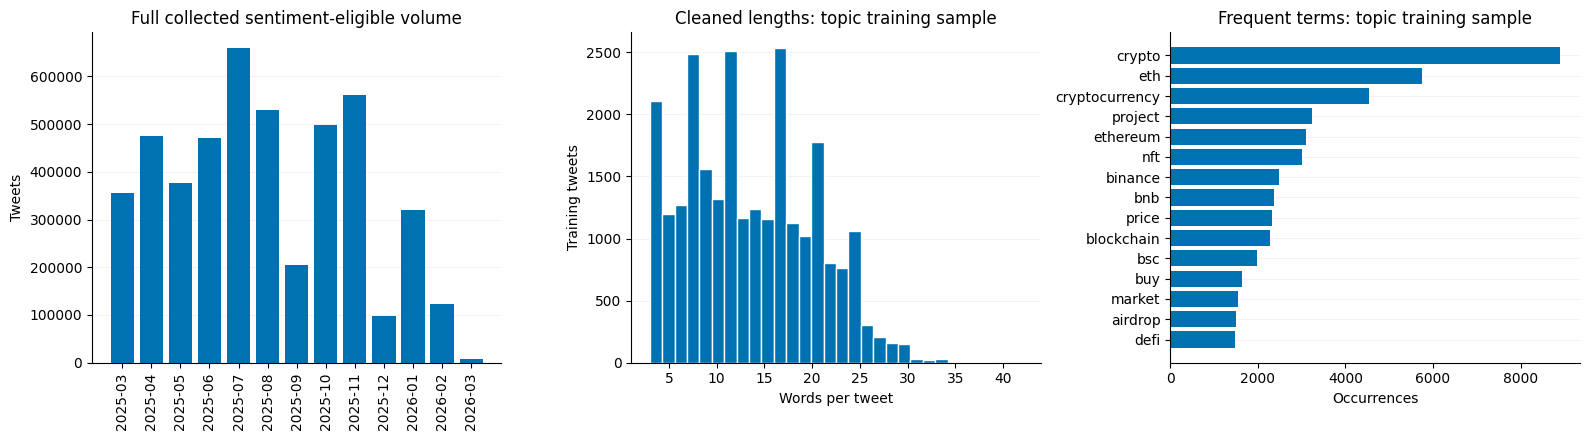

,Cleaned words per training tweet
count,26000.000000
mean,13.468346
std,6.609828
min,3.000000
25%,8.000000
50%,13.000000
75%,18.000000
max,42.000000


In [5]:
from collections import Counter

q1_volume = read_saved_csv('bitcoin_full_daily_volume.csv')
q1_volume['day'] = pd.to_datetime(q1_volume['day'], utc=True)
q1_volume = q1_volume.sort_values('day')
q1_monthly_volume = q1_volume.groupby(
    q1_volume['day'].dt.strftime('%Y-%m')
)['full_tweet_count'].sum()
q1_lengths = model_df['clean_topic_text'].fillna('').str.split().str.len()
term_counts = Counter()
for text in model_df['clean_topic_text'].fillna(''):
    term_counts.update(text.split())
top_terms = pd.DataFrame(term_counts.most_common(15), columns=['Term', 'Count'])

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].bar(q1_monthly_volume.index, q1_monthly_volume.values, color='#0072B2')
axes[0].set(title='Full collected sentiment-eligible volume', ylabel='Tweets')
axes[0].tick_params(axis='x', rotation=90)
axes[1].hist(q1_lengths, bins=30, color='#0072B2', edgecolor='white')
axes[1].set(title='Cleaned lengths: topic training sample',
            xlabel='Words per tweet', ylabel='Training tweets')
axes[2].barh(top_terms['Term'][::-1], top_terms['Count'][::-1], color='#0072B2')
axes[2].set(title='Frequent terms: topic training sample', xlabel='Occurrences')
for ax in axes:
    ax.spines[['top', 'right']].set_visible(False)
    ax.set_axisbelow(True)
    ax.grid(axis='y', alpha=0.15)
fig.tight_layout()
fig.savefig(RUN_DIR / 'bitcoin_topic_saved_data_eda.png', dpi=180, bbox_inches='tight')
plt.show()
display(q1_lengths.describe().to_frame('Cleaned words per training tweet'))


## Q1.3 — Topic-count evidence and the final model settings

The original NMF evaluation compared **5, 7, 9, 11 and 13 topics** using
reconstruction error, word co-occurrence coherence, keyword diversity and
stability across two seeds. We retained **nine topics**. The topic-count table
was not separately exported in the earlier save, so these are recorded historical
values from its output; Appendix A retains the evaluation code; the reference values are preserved here.

| Topics | Reconstruction error | Coherence | Diversity | Stability |
|---:|---:|---:|---:|---:|
| 5 | 157.915339 | -0.799463 | 0.960000 | 0.772700 |
| 7 | 157.102605 | -1.058880 | 0.957143 | 0.710368 |
| 9 | 156.469075 | -0.956105 | 0.955556 | 0.875123 |
| 11 | 155.892537 | -1.131176 | 0.954545 | 0.884320 |
| 13 | 155.441853 | -1.232112 | 0.953846 | 0.830957 |

Final comparison: **CountVectorizer → LDA** and **TF-IDF → NMF**, on the same
sample, with 5,000 features, unigrams/bigrams, `min_df=5`, `max_df=0.95`, English
stop words and seed 42. LDA used online learning, 15 iterations and batch size
256. Final NMF used `init='nndsvda'` and 500 iterations. These final settings are
distinct from the preliminary topic-count evaluation settings.

The saved `tfidf_matrix.npz` is from the preliminary representation; do not assume
its columns match the separately saved final TF-IDF vectoriser.

**Why nine topics:** this is a compromise between thematic detail and stability,
not the best value of every metric. The nine-topic preliminary model had stability
0.875, much higher than seven topics (0.710), and diversity 0.956. Eleven topics
had slightly higher stability (0.884) but worse coherence; thirteen also had worse
coherence and lower stability than nine. Five topics had better coherence but
offered less thematic detail. The preliminary diagnostic settings differ from the
final fit, so this evidence supports a judgement rather than proving an optimum.
The final labels and representative tweets are the accompanying semantic check.


In [6]:
# Optional: load the fitted models. No fit or transform is called here.
if LOAD_TOPIC_MODELS:
    import joblib
    nmf_model = joblib.load(ARTIFACT_PATHS['nmf_topic_model.joblib'])
    tfidf_vectorizer = joblib.load(ARTIFACT_PATHS['tfidf_vectorizer.joblib'])
    lda_model = joblib.load(ARTIFACT_PATHS['lda_topic_model.joblib'])
    count_vectorizer = joblib.load(ARTIFACT_PATHS['count_vectorizer.joblib'])
    print('Saved LDA/NMF models and final vectorisers loaded.')
else:
    print('Model files located in Drive; loading is optional for this review.')


Model files located in Drive; loading is optional for this review.


## Q1.4 : Compare model quality and inspect interpretation

Coherence, diversity, topic balance and representative tweets provide different
types of evidence. The completed comparison favoured NMF's coherence and keyword
diversity, while LDA had more balanced topic sizes. NMF was selected with this
tradeoff documented; the metrics do not establish that every topic is correct.


In [7]:
model_comparison = read_saved_csv('lda_nmf_model_comparison.csv')
representative_comparison = read_saved_csv('lda_nmf_representative_tweets.csv')
display(model_comparison.round(3))
display(representative_comparison.groupby(['Model', 'Topic'], sort=True).head(1))


,Model,Coherence,Diversity,Topic balance,Largest topic (%)
0,LDA,-2.275,0.767,0.953,19.892
1,NMF,-1.249,0.956,0.732,42.131


,Model,Topic,Score,Tweet
0,LDA,0,0.965808,"💣 #BTC and 78 Others, 🟢 60 🔴 19\n\n🇰🇷 130.88억원\n🇺🇸 $11,199,261\n🇯🇵 ¥1,230,108,383\n🇪🇺 €9,478,818\n🇨🇳 72,299,360元\n\n🎉Upflow volume Now, Upbit(Korea)\n#BTC ..."
3,LDA,1,0.977204,Buy now. \n400 minted and counting - 0.005 eth only\n#nfts #nft #nftart #nftcommunity #nftcollector #nftartist #cryptoart #digitalart #art #crypto #ethereum...
6,LDA,2,0.955540,"Analyst compares Bitcoin's price action to Nasdaq in the early 2000s and says BTC correction below $30,000 is on the horizon #2000s #Action #analyst #Bitcoi..."
9,LDA,3,0.957665,"🇦🇺 #Bitcoin (BTC) Arbitrage occured in Australia ‼\n ✅BestAsk Exchange:Independent Reserve\n ⬇Price (BUY): 1BTC = 43,965 AUD\n ✅BestBid Exchange:Coinspot..."
12,LDA,4,0.977777,#Orijin #Polygon #IDO #BSC #Eth #BTC #Airdrop #DeFi #Launchpad\nThis is really very cool and strong project with great facilities. I hope this project will ...
15,LDA,5,0.973056,@0x_aliceth CREOENGINE🚀\n🚀Decentralised #Marketplace for #NFTs \n🚀#Decentralised gaming Ecosystem \n🚀#NFT #gaming to Play and Earn\nAudited by @CertiKTech &...
18,LDA,6,0.975305,[Scan results - #Binance - 15m]\n\nTop 5 bullish trend on #BTC pair\n1: $BAL\n2: $GRT\n3: $KNC\n4: $MIR\n5: $CVX\n\nTop 5 bullish trend on #USDT pair\n1: $K...
21,LDA,7,0.973064,"30 USD on #ElSalvador #BitcoinDay got you 63,900 sat. \nNow 63,900 sat are 13.89 USD (-53.72%)\n\n1 BTC = 21,728.80 USD\n1 USD = 4,602 Sat\non Sun 11 Sep 20..."
24,LDA,8,0.974603,#linkedin #twitter #facebook #instagram #bitcoin #socialmedia #pinterest #medium #birthdayboy #reddit #gift #gifts #giftideas #shop #shopping #affiliatemark...
27,NMF,0,0.119901,#Bitcoin may clash again 🤔🚨\n\n#BTC #Crypto #Cryptocurrency #คริปโต #คริปโตเคอร์เรนซี


## Q1.5 : Label and summarise the selected NMF topics

Labels describe the keywords and representative tweets. The corpus includes
other coins, promotions and automated alerts as well as Bitcoin discussion;
the labels reflect the actual dataset. An NMF weight normalised across a tweet's
topics is a relative weight, not a calibrated probability of topic correctness.


,nmf_topic,nmf_topic_label,tweet_count,percentage,average_score,top_keywords
0,0,General Cryptocurrency News and Blockchain,3930,15.12,0.615,"crypto, cryptocurrency, blockchain, crypto cryptocurrency, ethereum, cryptonews, trading, binance, altcoin, cryptocurrencies, news, cryptocurrency ethereum"
1,1,Lightning Network and Bitcoin Faucets,590,2.27,0.810,"free lightning, lightning sats, lightningnetwork boltcoiner, boltcoiner, faucet, unlock, lightningnetwork, sats, lightning, free, making tweet, sats unlock"
2,2,Coinhunt Cryptocurrency Gaming,345,1.33,0.820,"playing coinhuntworld, join playing, coinhuntworld awesome, coinhuntworld, awesome cryptocurrency, vault, vault location, location, location join, playing, ..."
3,3,Airdrops and Promotional Campaigns,2709,10.42,0.717,"project, airdrop, bsc, good, airdrops, great, future, good project, team, airdrop airdrops, airdropinspector, airdrops airdropinspector"
4,4,Cardano Price Alerts,580,2.23,0.642,"cardano price, cardano, price, usd, ada usd, updates altcoin, alert ada, price updates, current cardano, price alert, recent cardano, follow recent"
5,5,Trading and Market Discussion,10954,42.13,0.738,"buy, just, time, market, price, like, long, people, bullish, going, sell, money"
6,6,"NFTs, Metaverse and Meme Coins",5807,22.33,0.620,"nft, eth, nfts, bnb, nftcommunity, metaverse, ethereum, doge, solana, binance, nftart, shib"
7,7,Whale and Volume Alerts,629,2.42,0.680,"volume, whale, alert, price, min, crypto whale, volume price, min volume, volume crypto, whale eth, price min, bear alert"
8,8,Bitcoin Mining and Block Rewards,456,1.75,0.695,"block, mined, value, remaining, gmt value, tictoknextblock, mined remaining, remaining tictoknextblock, distributed recipients, recipients mined, recipients..."


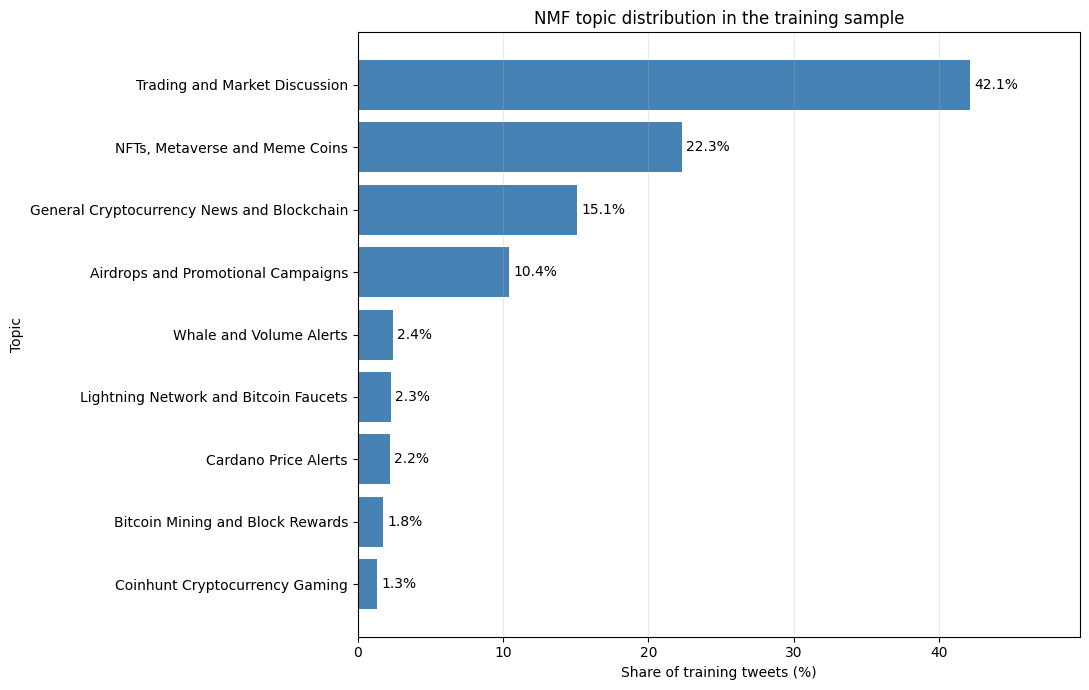

In [8]:
nmf_final_summary = read_saved_csv('nmf_final_topic_summary.csv')
nmf_topic_labels = dict(zip(
    nmf_final_summary['nmf_topic'], nmf_final_summary['nmf_topic_label']
))
display(nmf_final_summary.round({'percentage': 2, 'average_score': 3}))

plot_data = nmf_final_summary.sort_values('percentage')
fig, ax = plt.subplots(figsize=(11, 7))
bars = ax.barh(plot_data['nmf_topic_label'], plot_data['percentage'], color='steelblue')
ax.bar_label(bars, fmt='%.1f%%', padding=3)
ax.set(title='NMF topic distribution in the training sample',
       xlabel='Share of training tweets (%)', ylabel='Topic')
ax.set_xlim(0, plot_data['percentage'].max() * 1.18)
ax.grid(axis='x', alpha=0.25)
fig.tight_layout()
plt.show()


### Q1.5b — Interpret every selected topic

The table pairs each final NMF label and its keywords with a short interpretation.
Three high-scoring tweets per topic are shown separately using original text.
These are model-selected illustrations, not evidence that every assigned tweet
is correctly classified. Promotional and other-coin themes describe the corpus
and should not be relabelled as exclusively Bitcoin discussion.


In [9]:
topic_interpretations = {
    0: 'Broad cryptocurrency news, blockchain projects and ecosystem discussion.',
    1: 'Lightning payments and promotions offering small amounts of bitcoin or sats.',
    2: 'Posts encouraging participation in CoinhuntWorld and its location-based rewards.',
    3: 'Airdrops, giveaways and project promotion, often using repeated campaign wording.',
    4: 'Recurring Cardano/ADA price updates; this is other-coin content in the supplied corpus.',
    5: 'Trading opinions, buying and selling, market direction and price expectations.',
    6: 'NFTs, metaverse projects and meme-coin promotion across the wider crypto ecosystem.',
    7: 'Whale transactions, unusual trading volume and automated market alerts.',
    8: 'Mining announcements, newly mined blocks, rewards and remaining bitcoin supply.'
}
final_topic_interpretation = nmf_final_summary.copy()
final_topic_interpretation['interpretation'] = (
    final_topic_interpretation['nmf_topic'].map(topic_interpretations)
)
if final_topic_interpretation['interpretation'].isna().any():
    raise ValueError('A final topic is missing its interpretation.')

final_representative_tweets = (
    model_df.sort_values(['nmf_topic', 'nmf_score'], ascending=[True, False])
    .groupby('nmf_topic', sort=True).head(3)
    [['row_id', 'date', 'nmf_topic', 'nmf_score', 'text']].copy()
)
final_representative_tweets['nmf_topic_label'] = (
    final_representative_tweets['nmf_topic'].map(nmf_topic_labels)
)
if set(final_representative_tweets['nmf_topic']) != set(nmf_final_summary['nmf_topic']):
    raise ValueError('Representative tweets do not cover every final NMF topic.')
final_topic_interpretation.to_csv(
    RUN_DIR / 'nmf_final_topic_interpretation.csv', index=False, encoding='utf-8-sig'
)
final_representative_tweets.to_csv(
    RUN_DIR / 'nmf_final_representative_tweets.csv', index=False, encoding='utf-8-sig'
)
with pd.option_context('display.max_colwidth', None, 'display.max_rows', 40):
    display(final_topic_interpretation[
        ['nmf_topic', 'nmf_topic_label', 'top_keywords', 'interpretation']
    ])
    display(final_representative_tweets)


,nmf_topic,nmf_topic_label,top_keywords,interpretation
0,0,General Cryptocurrency News and Blockchain,"crypto, cryptocurrency, blockchain, crypto cryptocurrency, ethereum, cryptonews, trading, binance, altcoin, cryptocurrencies, news, cryptocurrency ethereum","Broad cryptocurrency news, blockchain projects and ecosystem discussion."
1,1,Lightning Network and Bitcoin Faucets,"free lightning, lightning sats, lightningnetwork boltcoiner, boltcoiner, faucet, unlock, lightningnetwork, sats, lightning, free, making tweet, sats unlock",Lightning payments and promotions offering small amounts of bitcoin or sats.
2,2,Coinhunt Cryptocurrency Gaming,"playing coinhuntworld, join playing, coinhuntworld awesome, coinhuntworld, awesome cryptocurrency, vault, vault location, location, location join, playing, awesome, join",Posts encouraging participation in CoinhuntWorld and its location-based rewards.
3,3,Airdrops and Promotional Campaigns,"project, airdrop, bsc, good, airdrops, great, future, good project, team, airdrop airdrops, airdropinspector, airdrops airdropinspector","Airdrops, giveaways and project promotion, often using repeated campaign wording."
4,4,Cardano Price Alerts,"cardano price, cardano, price, usd, ada usd, updates altcoin, alert ada, price updates, current cardano, price alert, recent cardano, follow recent",Recurring Cardano/ADA price updates; this is other-coin content in the supplied corpus.
5,5,Trading and Market Discussion,"buy, just, time, market, price, like, long, people, bullish, going, sell, money","Trading opinions, buying and selling, market direction and price expectations."
6,6,"NFTs, Metaverse and Meme Coins","nft, eth, nfts, bnb, nftcommunity, metaverse, ethereum, doge, solana, binance, nftart, shib","NFTs, metaverse projects and meme-coin promotion across the wider crypto ecosystem."
7,7,Whale and Volume Alerts,"volume, whale, alert, price, min, crypto whale, volume price, min volume, volume crypto, whale eth, price min, bear alert","Whale transactions, unusual trading volume and automated market alerts."
8,8,Bitcoin Mining and Block Rewards,"block, mined, value, remaining, gmt value, tictoknextblock, mined remaining, remaining tictoknextblock, distributed recipients, recipients mined, recipients, distributed","Mining announcements, newly mined blocks, rewards and remaining bitcoin supply."


,row_id,date,nmf_topic,nmf_score,text,nmf_topic_label
13562,4170458,2025-09-13 15:49:56+00:00,0,1.000000,BTW Those are not minted because i have 0 income!\n#crypto #bitcoin #cryptocurrency #blockchain #ethereum #btc #forex #trading #cryptonews #cryptotrading #bitcoinmining,General Cryptocurrency News and Blockchain
25160,2342351,2026-03-02 21:55:20+00:00,0,1.000000,Blockchain Commons Announces #Bitcoin Internship Program\n\nhttps://t.co/b4FESxzvBz #BTC #Crypto #CryptoNews #CryptocurrencyNews,General Cryptocurrency News and Blockchain
3560,2832490,2025-04-22 22:01:29+00:00,0,1.000000,💰 CRYPTO BUYS (04/22/2022 18:01)\n- Convex Finance: $25.959\n- Decred: $64.439\n- Monero: $267.135\n#ConvexFinance #Decred #Monero #crypto #cryptotrading #coinbase #cryptocurrency #cryptomarket #bitcoin #ethereum #trading #investing,General Cryptocurrency News and Blockchain
1572,2645829,2025-03-23 07:50:36+00:00,1,1.000000,This zesty faucet from @_bitcoiner is making me tweet this to claim my free Lightning sats. ⚡\n\n@boltcoiner unlock me 8c7761c4-b989-44c8-96b1-a7abfe61ac46\n\n#Bitcoin #BTC #LN #LightningNetwork #boltcoiner\nhttps://t.co/Q2VeCrvKxb,Lightning Network and Bitcoin Faucets
1577,2644354,2025-03-23 09:11:25+00:00,1,1.000000,This zesty faucet from @_bitcoiner is making me tweet this to claim my free Lightning sats. ⚡\n\n@boltcoiner unlock me 9f904909-129f-4385-84df-1857d71a3a12\n\n#Bitcoin #BTC #LN #LightningNetwork #boltcoiner\nhttps://t.co/p9Tg5I7n7t,Lightning Network and Bitcoin Faucets
1666,2628515,2025-03-23 21:34:05+00:00,1,1.000000,This zesty faucet from @_bitcoiner is making me tweet this to claim my free Lightning sats. ⚡\n\n@boltcoiner unlock me cc344ba4-73b2-4a04-a6f4-267cdbfb6b9b\n\n#Bitcoin #BTC #LN #LightningNetwork #boltcoiner\nhttps://t.co/rIt961ZAa8,Lightning Network and Bitcoin Faucets
184,2396721,2025-03-08 23:42:01+00:00,2,1.000000,"Katertot723 found #bitcoin in a User vault at this location! Join me playing #coinhuntworld, It's awesome! https://t.co/6TiUdx6tRp #cryptocurrency #65275 https://t.co/EMbutv1fV0",Coinhunt Cryptocurrency Gaming
446,2349327,2025-03-10 20:35:24+00:00,2,1.000000,"Kracko64 found #bitcoin in a User vault at this location! Join me playing #coinhuntworld, It's awesome! https://t.co/wCp6R3Tidi #cryptocurrency #57060 https://t.co/MEQaUGED5I",Coinhunt Cryptocurrency Gaming
730,2519688,2025-03-16 09:29:51+00:00,2,1.000000,"Southof60 found #bitcoin in a User vault at this location! Join me playing #coinhuntworld, It's awesome! https://t.co/UtcvtiDySR #cryptocurrency #7645 https://t.co/fALymRYkvR",Coinhunt Cryptocurrency Gaming
17373,1781009,2025-11-19 06:49:15+00:00,3,1.000000,@AirdropStario Good project \n\n@Shanto414 \n@ekhan4788 \n@Rjrakib1122\n\n#cryptocurrecy #GENI #GemUni #Bitcoin #Airdrop #BSC #Airdropstario,Airdrops and Promotional Campaigns


## Q1.6 — Full-corpus assignment and monthly topic prevalence

The fitted NMF model was applied to the modelling base in chunks. The completed
run assigned **4,641,399 tweets** and marked **47,840 as unassigned** when no
usable recognised terms were available. The full-corpus assignment file remains
in Drive. Reloading its existing monthly summary avoids repeating those transforms.

Monthly shares use assigned tweets as the denominator and cover 13 supplied
months. They describe this dataset and its supplied timestamps; they are not
population estimates of all Bitcoin discussion.


,row_id,date,nmf_topic,nmf_topic_label,nmf_topic_score
0,1,2026-02-10 23:59:04,2,Coinhunt Cryptocurrency Gaming,0.721428
1,2,2026-02-10 23:58:48,5,Trading and Market Discussion,0.726980
2,3,2026-02-10 23:54:48,5,Trading and Market Discussion,0.843445
3,4,2026-02-10 23:54:33,5,Trading and Market Discussion,0.324626
4,5,2026-02-10 23:54:06,5,Trading and Market Discussion,0.846932
5,6,2026-02-10 23:53:30,0,General Cryptocurrency News and Blockchain,0.532512
6,7,2026-02-10 23:53:17,0,General Cryptocurrency News and Blockchain,0.757735
7,8,2026-02-10 23:52:42,6,"NFTs, Metaverse and Meme Coins",0.673117
8,9,2026-02-10 23:52:25,6,"NFTs, Metaverse and Meme Coins",0.337356
9,10,2026-02-10 23:52:08,5,Trading and Market Discussion,0.587526


,month,nmf_topic,nmf_topic_label,tweet_count,monthly_total,percentage
0,2025-03,0,General Cryptocurrency News and Blockchain,42231,352611,11.976654
1,2025-03,1,Lightning Network and Bitcoin Faucets,10161,352611,2.881646
2,2025-03,2,Coinhunt Cryptocurrency Gaming,2983,352611,0.845975
3,2025-03,3,Airdrops and Promotional Campaigns,32163,352611,9.121383
4,2025-03,4,Cardano Price Alerts,14213,352611,4.030787
5,2025-03,5,Trading and Market Discussion,120740,352611,34.241700
6,2025-03,6,"NFTs, Metaverse and Meme Coins",113119,352611,32.080395
7,2025-03,7,Whale and Volume Alerts,10893,352611,3.089240
8,2025-03,8,Bitcoin Mining and Block Rewards,6108,352611,1.732220
9,2025-04,0,General Cryptocurrency News and Blockchain,61616,471456,13.069300


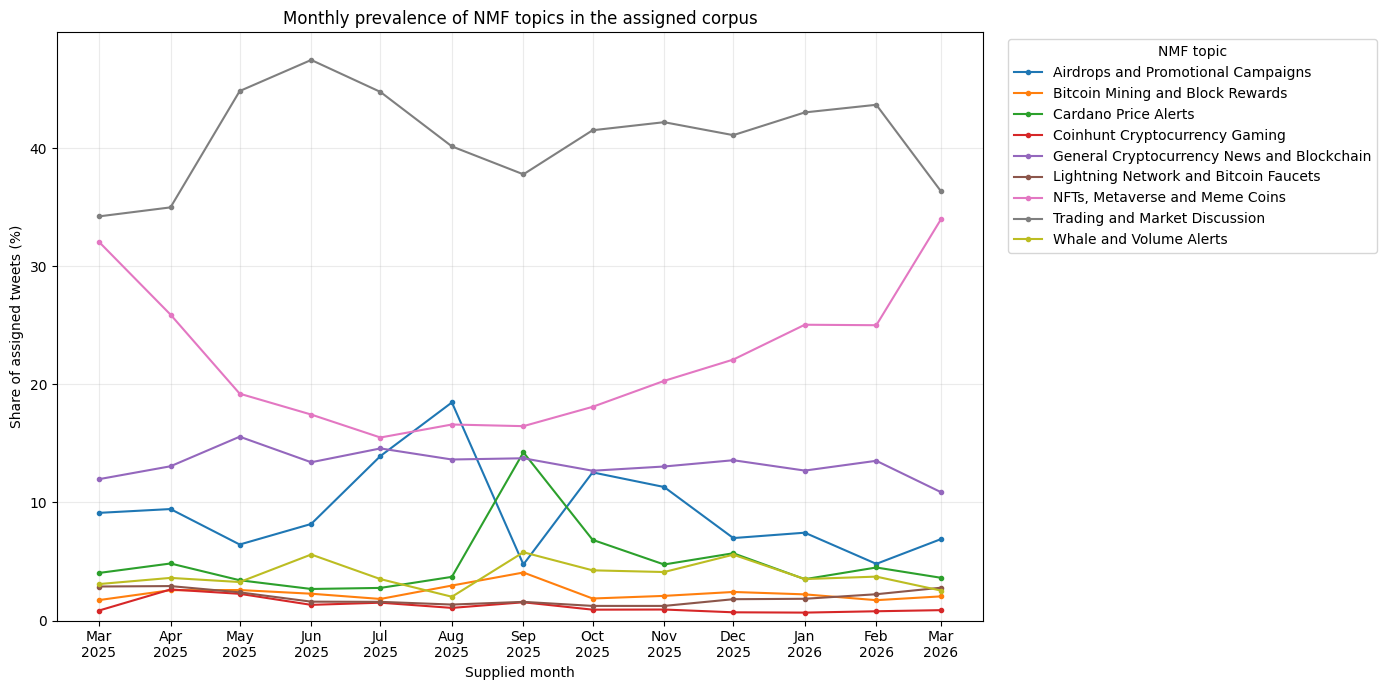

In [10]:
assignment_preview = read_saved_csv('bitcoin_nmf_topic_assignments.csv', nrows=10)
monthly_topic_prevalence = read_saved_csv('nmf_monthly_topic_prevalence.csv')
display(assignment_preview)
display(monthly_topic_prevalence.head(18))

plot_data = monthly_topic_prevalence.copy()
plot_data['month_date'] = pd.to_datetime(plot_data['month'], errors='raise')
fig, ax = plt.subplots(figsize=(14, 7))
for topic_label, topic_data in plot_data.groupby('nmf_topic_label'):
    topic_data = topic_data.sort_values('month_date')
    ax.plot(topic_data['month_date'], topic_data['percentage'],
            marker='o', markersize=3, label=topic_label)
ax.set(title='Monthly prevalence of NMF topics in the assigned corpus',
       xlabel='Supplied month', ylabel='Share of assigned tweets (%)')
ax.set_ylim(bottom=0)
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b\n%Y'))
ax.grid(alpha=0.25)
ax.legend(title='NMF topic', bbox_to_anchor=(1.02, 1), loc='upper left')
fig.tight_layout()
plt.show()


### Q1.6b — Explain the changes in topic prevalence

The monthly chart shows all supplied months. For endpoint comparisons below,
exclude the partly covered first and last calendar months. Other months may
still have missing collection days. Shares refer to assigned, collected tweets;
a higher share does not necessarily mean a higher absolute number of tweets.
Changes cannot be tied confidently to historical market events given the date concerns.


In [11]:
topic_shares = monthly_topic_prevalence.pivot(
    index='month', columns='nmf_topic_label', values='percentage'
).sort_index()
first_collected = q1_volume['day'].min().normalize()
last_collected = q1_volume['day'].max().normalize()
full_months = []
for month in topic_shares.index:
    start = pd.Timestamp(str(month) + '-01', tz='UTC')
    end = start + pd.offsets.MonthEnd(0)
    if first_collected <= start and last_collected >= end:
        full_months.append(month)
if len(full_months) < 2:
    raise ValueError('At least two fully bounded calendar months are needed for this comparison.')

comparable_shares = topic_shares.loc[full_months]
first_month, last_month = full_months[0], full_months[-1]
topic_changes = pd.DataFrame({
    'First_month': first_month,
    'First_share_pct': comparable_shares.iloc[0],
    'Last_month': last_month,
    'Last_share_pct': comparable_shares.iloc[-1],
    'Change_pp': comparable_shares.iloc[-1] - comparable_shares.iloc[0],
    'Peak_month': comparable_shares.idxmax(),
    'Peak_share_pct': comparable_shares.max()
}).sort_values('Change_pp', ascending=False)
topic_changes.index.name = 'Topic'
display(topic_changes.round(2))
topic_changes.to_csv(RUN_DIR / 'nmf_topic_change_summary.csv', encoding='utf-8-sig')

for label in topic_changes.head(2).index:
    row = topic_changes.loc[label]
    print(f"{label}: {row['First_share_pct']:.2f}% in {first_month} to "
          f"{row['Last_share_pct']:.2f}% in {last_month} "
          f"(change {row['Change_pp']:+.2f} percentage points).")
for label in topic_changes.tail(2).index:
    row = topic_changes.loc[label]
    print(f"{label}: {row['First_share_pct']:.2f}% in {first_month} to "
          f"{row['Last_share_pct']:.2f}% in {last_month} "
          f"(change {row['Change_pp']:+.2f} percentage points).")
print('These are changes in dataset composition under the supplied timestamps, not causal findings.')


,First_month,First_share_pct,Last_month,Last_share_pct,Change_pp,Peak_month,Peak_share_pct
Topic,,,,,,,
Trading and Market Discussion,2025-04,35.00,2026-02,43.70,8.69,2025-06,47.49
General Cryptocurrency News and Blockchain,2025-04,13.07,2026-02,13.53,0.46,2025-05,15.57
Whale and Volume Alerts,2025-04,3.61,2026-02,3.72,0.11,2025-09,5.78
Cardano Price Alerts,2025-04,4.83,2026-02,4.49,-0.34,2025-09,14.25
Lightning Network and Bitcoin Faucets,2025-04,2.92,2026-02,2.23,-0.69,2025-04,2.92
Bitcoin Mining and Block Rewards,2025-04,2.57,2026-02,1.72,-0.84,2025-09,4.07
"NFTs, Metaverse and Meme Coins",2025-04,25.92,2026-02,25.02,-0.90,2025-04,25.92
Coinhunt Cryptocurrency Gaming,2025-04,2.63,2026-02,0.78,-1.85,2025-04,2.63
Airdrops and Promotional Campaigns,2025-04,9.44,2026-02,4.80,-4.64,2025-08,18.48


Trading and Market Discussion: 35.00% in 2025-04 to 43.70% in 2026-02 (change +8.69 percentage points).
General Cryptocurrency News and Blockchain: 13.07% in 2025-04 to 13.53% in 2026-02 (change +0.46 percentage points).
Coinhunt Cryptocurrency Gaming: 2.63% in 2025-04 to 0.78% in 2026-02 (change -1.85 percentage points).
Airdrops and Promotional Campaigns: 9.44% in 2025-04 to 4.80% in 2026-02 (change -4.64 percentage points).
These are changes in dataset composition under the supplied timestamps, not causal findings.


## Q1.7 — Complete the required tweet-level submission file

Requirement 10 asks for row ID, date, **cleaned text**, assigned topic and score.
The original assignment file omitted cleaned text. The following one-time export
joins it from the existing cleaned corpus using row IDs. It checks matching IDs
and dates in each chunk before writing a separate completed file. Original
predictions and files are preserved; no topic model is loaded or transformed.

This works with the matching row order produced by the original pipeline. A
mismatch stops the export so unrelated records cannot be silently paired.
Unassigned records retain topic `-1`, label `Unassigned` and a missing score.


In [12]:
import json
from itertools import zip_longest

def complete_topic_export(folder, chunksize=100_000):
    folder = Path(folder)
    destination = folder / 'bitcoin_nmf_topic_assignments_complete.csv'
    manifest = folder / 'bitcoin_nmf_topic_assignments_complete_manifest.json'
    required = ['row_id', 'date', 'clean_topic_text', 'nmf_topic',
                'nmf_topic_label', 'nmf_topic_score']
    if destination.is_file():
        if pd.read_csv(destination, nrows=0).columns.tolist() != required:
            raise ValueError('Existing completed export has an unexpected schema.')
        print('Reusing completed topic export:', destination)
        if manifest.is_file():
            print('Previously verified rows:', f"{json.loads(manifest.read_text())['rows']:,}")
        return destination

    assignment_file = folder / 'bitcoin_nmf_topic_assignments.csv'
    cleaned_file = folder / 'bitcoin_topic_cleaned.csv'
    for path in [assignment_file, cleaned_file]:
        if not path.is_file():
            raise FileNotFoundError(f'Missing saved input: {path}')
    temporary = destination.with_suffix('.partial.csv')
    row_count = 0
    previous_id = 0
    print('Creating the completed export from saved CSVs; no model inference runs.')
    try:
        with pd.read_csv(assignment_file,
                         usecols=['row_id', 'date', 'nmf_topic', 'nmf_topic_label', 'nmf_topic_score'],
                         dtype={'row_id': 'string'},
                         chunksize=chunksize, encoding='utf-8-sig') as assignments,                  pd.read_csv(cleaned_file, usecols=['row_id', 'date', 'clean_topic_text'],
                         dtype='string', chunksize=chunksize,
                         encoding='utf-8-sig') as cleaned:
            for number, pair in enumerate(zip_longest(assignments, cleaned), start=1):
                assigned, texts = pair
                if assigned is None or texts is None or len(assigned) != len(texts):
                    raise ValueError('Saved files have different row counts or chunk boundaries.')
                if assigned['row_id'].isna().any() or texts['row_id'].isna().any():
                    raise ValueError('A saved input has missing row IDs.')
                if not assigned['row_id'].reset_index(drop=True).equals(
                    texts['row_id'].reset_index(drop=True)
                ):
                    raise ValueError('Saved files have different row ID order; review before joining.')
                ids = pd.to_numeric(assigned['row_id'], errors='raise').to_numpy()
                if len(ids) and (ids[0] <= previous_id or not (np.diff(ids) > 0).all()):
                    raise ValueError('Saved row IDs are repeated or out of original order.')
                assigned_dates = pd.to_datetime(assigned['date'], errors='raise', utc=True)
                text_dates = pd.to_datetime(texts['date'], errors='raise', utc=True)
                if not np.array_equal(assigned_dates.to_numpy(), text_dates.to_numpy()):
                    raise ValueError('Assignment and cleaned-text dates disagree.')
                joined = assigned.merge(
                    texts[['row_id', 'clean_topic_text']], on='row_id',
                    how='left', validate='one_to_one', sort=False
                )
                joined[required].to_csv(
                    temporary, mode='w' if number == 1 else 'a',
                    header=(number == 1), index=False, encoding='utf-8'
                )
                row_count += len(joined)
                previous_id = ids[-1] if len(ids) else previous_id
                if number % 10 == 0:
                    print(f'Rows copied and matched: {row_count:,}')
        if row_count == 0:
            raise ValueError('The source files contain no rows.')
        temporary.replace(destination)
        manifest.write_text(json.dumps({'rows': row_count, 'columns': required}, indent=2))
    except Exception:
        temporary.unlink(missing_ok=True)
        raise
    print(f'Completed export: {row_count:,} rows saved to {destination}')
    return destination

topic_submission_file = complete_topic_export(RUN_DIR)
display(pd.read_csv(topic_submission_file, nrows=5).fillna(''))


Creating the completed export from saved CSVs; no model inference runs.
Rows copied and matched: 1,000,000
Rows copied and matched: 2,000,000
Rows copied and matched: 3,000,000
Rows copied and matched: 4,000,000
Completed export: 4,689,239 rows saved to /content/drive/MyDrive/Assignment_4/Completed_Run/bitcoin_nmf_topic_assignments_complete.csv


,row_id,date,clean_topic_text,nmf_topic,nmf_topic_label,nmf_topic_score
0,1,2026-02-10 23:59:04,blue ridge bank shares halted nyse atm announcement,2,Coinhunt Cryptocurrency Gaming,0.721428
1,2,2026-02-10 23:58:48,today thursday friend wallet security expe,5,Trading and Market Discussion,0.726980
2,3,2026-02-10 23:54:48,guys evening read article like share,5,Trading and Market Discussion,0.843445
3,4,2026-02-10 23:54:33,big chance billion price crypto,5,Trading and Market Discussion,0.324626
4,5,2026-02-10 23:54:06,network secured nodes today soon biggest bears recognise big fail,5,Trading and Market Discussion,0.846932


# Question 2 — Sentiment and Bitcoin volatility

CryptoBERT provides sample-based daily sentiment estimates. Manual validation
yielded 43% agreement, so these estimates are noisy. We compare forecasts of
next-day absolute log returns using market inputs, market plus tweet volume,
and the same controls plus sentiment. A common chronological split makes the
comparisons fair. All conclusions remain conditional on supplied timestamps.


## Q2.1 — Tweet acquisition and sentiment preprocessing
### Assignment requirements 1–2: tweet data and sentiment preparation

Use the same prepared corpus as Question 1, but return to **original `text`**.
Sentiment preparation preserves negation, punctuation, emojis and hashtag wording;
it decodes HTML, removes the RT marker, replaces URLs with `HTTPURL`, replaces
mentions with `@USER`, and normalises whitespace. Essential missing fields,
exact date/text duplicates and prepared texts shorter than five characters were
excluded. This produced **4,686,913 sentiment-eligible tweets**.

The following function documents that agreed transformation for later use. It is
not reapplied to millions of tweets during restoration. Supplied timestamps are
interpreted as UTC, an explicit assumption. Unlike the topic-training sample,
the sentiment sample was not restricted to English. Other-coin and multilingual
content remain limitations. Bitcoin daily prices were acquired separately from Yahoo Finance and are restored in Q2.6.


In [13]:
def prepare_sentiment_text(text):
    text = html.unescape(str(text))
    text = re.sub(r'^\s*RT\s+', '', text, flags=re.IGNORECASE)
    text = re.sub(r'https?://\S+|www\.\S+', 'HTTPURL', text)
    text = re.sub(r'@\w+', '@USER', text)
    return re.sub(r'\s+', ' ', text).strip()

sentiment_sample = read_saved_csv('bitcoin_sentiment_sample.csv')
for column in ['date', 'day']:
    sentiment_sample[column] = pd.to_datetime(
        sentiment_sample[column], errors='raise', utc=True
    )

volume_table = read_saved_csv('bitcoin_full_daily_volume.csv')
volume_table['day'] = pd.to_datetime(volume_table['day'], errors='raise', utc=True)
full_daily_volume = volume_table.set_index('day')['full_tweet_count'].sort_index()
full_daily_volume.index.name = 'day'

if not full_daily_volume.index.is_unique:
    raise ValueError('Saved full daily volume has duplicate dates.')
if sentiment_sample['row_id'].isna().any() or sentiment_sample['row_id'].duplicated().any():
    raise ValueError('Saved sentiment sample has missing or duplicate row IDs.')
if sentiment_sample[['date', 'day', 'text', 'sentiment_text']].isna().any().any():
    raise ValueError('Saved sentiment sample has missing essential fields.')
if not sentiment_sample['day'].eq(sentiment_sample['date'].dt.floor('D')).all():
    raise ValueError('Sample day does not match its supplied UTC date.')

print(f'Full sentiment-eligible tweet count: {int(full_daily_volume.sum()):,}')
print(f'Saved daily sample: {len(sentiment_sample):,}')
print('Observed days:', sentiment_sample['day'].nunique())
display(sentiment_sample[['row_id', 'date', 'text', 'sentiment_text']].head())


Full sentiment-eligible tweet count: 4,686,913
Saved daily sample: 40,083
Observed days: 201


,row_id,date,text,sentiment_text
0,2433882,2025-03-06 14:43:32+00:00,Goo green candle.. go #Brise \n$brise #ETH #btc #SolanaNFTs #ftm #bnb #Shib https://t.co/0KSocvPRox,Goo green candle.. go #Brise $brise #ETH #btc #SolanaNFTs #ftm #bnb #Shib HTTPURL
1,2433803,2025-03-06 14:48:08+00:00,"As expected #Bitcoin bounced from the $38,000 area. #BTC needs to hold or close a candle above the support $38,700 area for an upside move. We will see some...","As expected #Bitcoin bounced from the $38,000 area. #BTC needs to hold or close a candle above the support $38,700 area for an upside move. We will see some..."
2,2433799,2025-03-06 14:48:19+00:00,the strongest bullish signal flashed for #Bitcoin. Not trend reverse but price bounce is anticipated!\n\n@Tradecrypto11 is a super #BTC Trader \nI’ve been f...,the strongest bullish signal flashed for #Bitcoin. Not trend reverse but price bounce is anticipated! @USER is a super #BTC Trader I’ve been following his t...
3,2433780,2025-03-06 14:49:14+00:00,You can do Cloud Mining using this site https://t.co/Mo3wxvFXkb #mining #trxmining #money #earnmoney #register #bitcoin #ethereum #btc #eth #tronvex 2528,You can do Cloud Mining using this site HTTPURL #mining #trxmining #money #earnmoney #register #bitcoin #ethereum #btc #eth #tronvex 2528
4,2433777,2025-03-06 14:49:33+00:00,"BITCOIN PRICE PREDICTION\n\nPRICE : FALL⤵ in 60 min.\nTarget price : 38,507.37 USDT\nSELL 0.10 BTC for 38,896.33 USDT apiece on Binance\n(Amount: 3,890 USDT...","BITCOIN PRICE PREDICTION PRICE : FALL⤵ in 60 min. Target price : 38,507.37 USDT SELL 0.10 BTC for 38,896.33 USDT apiece on Binance (Amount: 3,890 USDT) #Bit..."


## Q2.2 — Coverage and the daily sampling decision
### Supporting requirements 2–3: what our sentiment estimates represent

The corpus covers 201 observed days across 362 calendar days, leaving 161 days
without collected tweets. These gaps do not establish that discussion was absent.
The coverage table below uses zero only to identify missing collection days;
missing sentiment must remain missing, not become a neutral score.

For inference we selected **up to 200 random tweets per observed day**, seed
`42 + day_number`, yielding 40,083 tweets. We have scored this sample, not all
4.7 million tweets. Later daily sentiment estimates are based on each day's
sample; volume uses the full sentiment-eligible corpus. Sampling uncertainty,
the daily cap and model errors need to be stated in the report.


In [14]:
TWEETS_PER_DAY = 200
daily_counts = full_daily_volume.rename('tweet_count')
calendar = pd.date_range(daily_counts.index.min(), daily_counts.index.max(), freq='D')
coverage = daily_counts.reindex(calendar, fill_value=0).to_frame()
coverage.index.name = 'day'
coverage['has_tweets'] = coverage['tweet_count'] > 0
coverage['month'] = coverage.index.strftime('%Y-%m')
monthly_coverage = coverage.groupby('month').agg(
    calendar_days=('tweet_count', 'size'),
    observed_days=('has_tweets', 'sum'),
    total_tweets=('tweet_count', 'sum')
)
monthly_coverage['missing_days'] = (
    monthly_coverage['calendar_days'] - monthly_coverage['observed_days']
)
missing_days = coverage.index[~coverage['has_tweets']]
sample_daily_counts = sentiment_sample.groupby('day').size().rename('sample_tweet_count')
expected_sample_counts = full_daily_volume.clip(upper=TWEETS_PER_DAY)
if not sample_daily_counts.reindex(expected_sample_counts.index).eq(expected_sample_counts).all():
    raise ValueError('Sample counts do not match the agreed cap of 200 tweets per observed day.')

print('Calendar days:', len(calendar))
print('Days with collected tweets:', int(coverage['has_tweets'].sum()))
print('Days without collected tweets:', len(missing_days))
display(monthly_coverage)
print('First 20 missing dates:', missing_days[:20].strftime('%Y-%m-%d').tolist())


Calendar days: 362
Days with collected tweets: 201
Days without collected tweets: 161


,calendar_days,observed_days,total_tweets,missing_days
month,,,,
2025-03,26,18,355362,8
2025-04,30,24,475105,6
2025-05,31,16,377591,15
2025-06,30,18,471917,12
2025-07,31,24,659520,7
2025-08,31,20,530638,11
2025-09,30,9,205530,21
2025-10,31,16,498097,15
2025-11,30,20,561596,10


First 20 missing dates: ['2025-03-13', '2025-03-25', '2025-03-26', '2025-03-27', '2025-03-28', '2025-03-29', '2025-03-30', '2025-03-31', '2025-04-01', '2025-04-02', '2025-04-03', '2025-04-04', '2025-04-25', '2025-04-26', '2025-05-03', '2025-05-04', '2025-05-05', '2025-05-06', '2025-05-07', '2025-05-08']


## Q2.3 — Restore completed CryptoBERT scores and explain the rules
### Assignment requirement 3: polarity and sentiment labels

CryptoBERT (`ElKulako/cryptobert`) was loaded and checked on ten tweets, then
applied to the daily sample in batches of eight with a 128-token input limit.
Its class order is Bearish, Neutral, Bullish, mapped to negative, neutral, positive.

For every sampled tweet:

- **Polarity = P(positive) − P(negative)**, bounded from −1 to +1.
- **Sentiment label = the class with the highest predicted probability.**

A slightly positive polarity can coexist with a neutral label when neutral has
the largest probability. There is no separate positive/negative threshold.
These are model-derived measures of market stance, not verified investor intentions.

The completed scoring used checkpoints every 200 tweets. This cell reads the
finished output; it does not download or call CryptoBERT. We check IDs, text,
probabilities and polarity so a mismatched or incomplete result is not accepted.

Model documentation: https://huggingface.co/ElKulako/cryptobert


In [15]:
sentiment_scored = read_saved_csv('bitcoin_sentiment_scored.csv')
for column in ['date', 'day']:
    sentiment_scored[column] = pd.to_datetime(
        sentiment_scored[column], errors='raise', utc=True
    )
if sentiment_scored['row_id'].isna().any() or sentiment_scored['row_id'].duplicated().any():
    raise ValueError('Scored file has missing or duplicate row IDs.')
if len(sentiment_scored) != len(sentiment_sample):
    raise ValueError('Scored file and sample have different row counts.')
if sentiment_scored[SCORE_COLUMNS].isna().any().any():
    raise ValueError('Some sampled tweets are missing complete predictions.')

aligned = sentiment_sample[['row_id', 'sentiment_text', 'date', 'day']].merge(
    sentiment_scored[['row_id', 'sentiment_text', 'date', 'day']],
    on='row_id', how='outer', suffixes=('_sample', '_scored'),
    indicator=True, validate='one_to_one'
)
if not aligned['_merge'].eq('both').all():
    raise ValueError('Sample and scored tweet IDs do not match.')
for column in ['sentiment_text', 'date', 'day']:
    if not aligned[f'{column}_sample'].eq(aligned[f'{column}_scored']).all():
        raise ValueError(f'Scored file is inconsistent with the saved sample: {column}')

probabilities = sentiment_scored[['p_negative', 'p_neutral', 'p_positive']].to_numpy()
if not np.isfinite(probabilities).all() or not ((probabilities >= 0) & (probabilities <= 1)).all():
    raise ValueError('Saved probabilities are outside the expected bounds.')
if not np.allclose(probabilities.sum(axis=1), 1, atol=1e-5):
    raise ValueError('Saved class probabilities do not sum to one.')
if not np.allclose(sentiment_scored['polarity'], probabilities[:, 2] - probabilities[:, 0], atol=1e-5):
    raise ValueError('Saved polarity does not follow the agreed probability rule.')
expected_labels = np.array(LABELS)[probabilities.argmax(axis=1)]
if not sentiment_scored['sentiment_label'].eq(expected_labels).all():
    raise ValueError('Saved labels do not match the largest class probability.')

print(f'Completed predictions restored and verified: {len(sentiment_scored):,}')
print('Observed days:', sentiment_scored['day'].nunique())
display(sentiment_scored['sentiment_label'].value_counts().reindex(LABELS, fill_value=0))
display(sentiment_scored[['row_id', 'date', 'text', 'polarity', 'sentiment_label']].head())
del aligned  # The consistency-check merge is no longer needed.


Completed predictions restored and verified: 40,083
Observed days: 201


,count
sentiment_label,
negative,2158
neutral,19078
positive,18847


,row_id,date,text,polarity,sentiment_label
0,2433882,2025-03-06 14:43:32+00:00,Goo green candle.. go #Brise \n$brise #ETH #btc #SolanaNFTs #ftm #bnb #Shib https://t.co/0KSocvPRox,0.767255,positive
1,2433803,2025-03-06 14:48:08+00:00,"As expected #Bitcoin bounced from the $38,000 area. #BTC needs to hold or close a candle above the support $38,700 area for an upside move. We will see some...",0.150663,neutral
2,2433799,2025-03-06 14:48:19+00:00,the strongest bullish signal flashed for #Bitcoin. Not trend reverse but price bounce is anticipated!\n\n@Tradecrypto11 is a super #BTC Trader \nI’ve been f...,0.476971,neutral
3,2433780,2025-03-06 14:49:14+00:00,You can do Cloud Mining using this site https://t.co/Mo3wxvFXkb #mining #trxmining #money #earnmoney #register #bitcoin #ethereum #btc #eth #tronvex 2528,0.218709,neutral
4,2433777,2025-03-06 14:49:33+00:00,"BITCOIN PRICE PREDICTION\n\nPRICE : FALL⤵ in 60 min.\nTarget price : 38,507.37 USDT\nSELL 0.10 BTC for 38,896.33 USDT apiece on Binance\n(Amount: 3,890 USDT...",0.481200,neutral


## Q2.4 — Restore manual validation and examine common errors
### Assignment requirement 4: at least 50 manually labelled tweets

A reproducible random sample of **100 tweets** was presented without model
predictions and labelled manually as negative, neutral or positive. We retain
those judgements. The review CSV may use semicolons after an Excel export, so
the reader detects its separator. We never overwrite it with a new blank template
during normal use.

The saved validation file contains the independent model predictions. We reload
them and recalculate accuracy, the classification report and confusion matrix
without running inference. Accuracy measures agreement with this manual review;
the human labels can also be ambiguous. The majority-label baseline provides
context for interpreting performance.


In [16]:
manual_labels = read_saved_csv('manual_sentiment_review.csv', sep=None, engine='python')
validation_results = read_saved_csv('cryptobert_manual_validation.csv')
error_examples = read_saved_csv('cryptobert_error_examples.csv')

for frame, name in [(manual_labels, 'manual review'), (validation_results, 'validation')]:
    frame['manual_label'] = frame['manual_label'].astype('string').str.strip().str.lower()
    if frame['row_id'].isna().any() or frame['row_id'].duplicated().any():
        raise ValueError(f'Saved {name} has missing or duplicate row IDs.')
    if not frame['manual_label'].isin(LABELS).all():
        raise ValueError(f'Saved {name} contains blank or invalid manual labels.')
if len(manual_labels) < 50:
    raise ValueError('The assignment requires at least 50 manually labelled tweets.')
if not validation_results['cryptobert_label'].isin(LABELS).all():
    raise ValueError('Saved validation contains invalid model labels.')

review_match = manual_labels[['row_id', 'text', 'manual_label']].merge(
    validation_results[['row_id', 'text', 'manual_label']], on='row_id',
    how='outer', suffixes=('_manual', '_validation'), indicator=True,
    validate='one_to_one'
)
if not review_match['_merge'].eq('both').all():
    raise ValueError('Manual review IDs and saved validation IDs do not match.')
for column in ['text', 'manual_label']:
    if not review_match[f'{column}_manual'].eq(review_match[f'{column}_validation']).all():
        raise ValueError(f'Manual review and saved validation differ in {column}.')
review_sample = manual_labels[['row_id', 'text']].merge(
    sentiment_sample[['row_id', 'text']], on='row_id', how='left',
    suffixes=('_manual', '_sample'), validate='one_to_one'
)
if not review_sample['text_manual'].eq(review_sample['text_sample']).all():
    raise ValueError('The manually reviewed tweets do not belong to the restored sample.')

validation_results['agreement'] = (
    validation_results['manual_label'] == validation_results['cryptobert_label']
)
accuracy = accuracy_score(validation_results['manual_label'], validation_results['cryptobert_label'])
majority_baseline = validation_results['manual_label'].value_counts(normalize=True).max()
confusion = pd.DataFrame(
    confusion_matrix(validation_results['manual_label'], validation_results['cryptobert_label'], labels=LABELS),
    index=pd.Index(LABELS, name='Your label'),
    columns=pd.Index(LABELS, name='CryptoBERT label')
)
print('Tweets evaluated:', len(validation_results))
print('Matching labels:', int(validation_results['agreement'].sum()))
print(f'Accuracy against manual labels: {accuracy:.1%}')
print(f'Majority-label baseline on this review: {majority_baseline:.1%}')
print(classification_report(
    validation_results['manual_label'], validation_results['cryptobert_label'],
    labels=LABELS, zero_division=0
))
display(confusion)
display(error_examples)
del review_match, review_sample


Tweets evaluated: 100
Matching labels: 43
Accuracy against manual labels: 43.0%
Majority-label baseline on this review: 46.0%
              precision    recall  f1-score   support

    negative       0.40      0.18      0.25        11
     neutral       0.39      0.35      0.37        43
    positive       0.46      0.57      0.50        46

    accuracy                           0.43       100
   macro avg       0.42      0.37      0.38       100
weighted avg       0.42      0.43      0.42       100



CryptoBERT label,negative,neutral,positive
Your label,,,
negative,2,4,5
neutral,2,15,26
positive,1,19,26


,row_id,text,manual_label,cryptobert_label,discussion_note
0,2209569,Another power move to push us into lower lows on #BTC.\n\nCheck out my blog for a detailed scan of the crypto markets\nhttps://t.co/IJmQ5EYHDA\n$BTC $ETH $D...,negative,neutral,The phrase 'lower lows' expresses a bearish outlook; CryptoBERT classified it as neutral.
1,2385613,"#BTC price now is: 41,834.367USD and the Day's range: 38706.094 - 42455.742 #Bitcoin #bitcoin #blockchain $BTC",neutral,negative,Factual price update without an explicit bearish opinion; CryptoBERT classified it as negative.
2,1887857,🔥🔥🔥 🐳🚨 Bitcoin Whale Alert: [ TX: 3ef0b984688aff5a119a01c5c42861d01a20c03a34586bc3d86122c9e3524752 ]-[ ADDR: 3AZZsxv9kejFtagE2ytTmxJLg1CYnwoAqb ]-[ #BTC: 31...,neutral,positive,Whale transaction alert without an explicit bullish outlook; CryptoBERT classified it as positive.
3,4439250,As long as $17k holds this is the bottom. The short liquidity is at $24k. Huge long opportunity for bitcoin. +50% move is plausible #btc,positive,neutral,A conditional bullish outlook describing a long opportunity and possible upward move; CryptoBERT classified it as neutral.


### What the validation means for the report

The completed review yielded **43/100 matching labels (43%)**, against a
**46% majority-positive baseline**. Negative recall was about 18%, neutral recall
35% and positive recall 57%. This is weak agreement on this review, so successful
execution must not be presented as strong sentiment accuracy. Report the original
labels and results rather than adjusting judgements to increase agreement.

The saved cases illustrate factual price updates interpreted as negative,
whale-transaction alerts interpreted as positive, bearish jargon such as
“lower lows” missed as neutral, and conditional bullish statements missed as
neutral. The cases are illustrations, not estimates of each error type's prevalence.
Other-coin content, multilingual tweets and ambiguous manual labels also matter.

We will continue with the agreed CryptoBERT measure while making these limitations
explicit in later modelling and interpretation.


## Q2.5 — Restore daily sentiment aggregation
### Assignment requirement 5

The saved table contains mean probability polarity, negative/neutral/positive
label shares, scored sample size, full collected volume and a coverage flag.
There are 201 observed sentiment days on a 362-day calendar. Days without
collected tweets have missing sentiment, not a neutral score. Full volume is
distinct from the daily inference cap of 200 tweets.


In [17]:
daily_sentiment = read_daily_csv('bitcoin_daily_sentiment.csv')
calendar = pd.date_range(daily_sentiment.index.min(), daily_sentiment.index.max(), freq='D')
if not daily_sentiment.index.equals(calendar):
    raise ValueError('Saved daily sentiment must retain the complete calendar.')
observed = daily_sentiment['sample_tweet_count'] > 0
daily_sentiment['has_sentiment'] = observed
shares = [f'{label}_share' for label in LABELS]
if daily_sentiment['sample_tweet_count'].sum() != len(sentiment_scored):
    raise ValueError('Daily counts do not match restored tweet predictions.')
if not np.allclose(daily_sentiment.loc[observed, shares].sum(axis=1), 1):
    raise ValueError('Observed daily sentiment shares do not sum to one.')
if not daily_sentiment.loc[~observed, ['mean_polarity'] + shares].isna().all().all():
    raise ValueError('Missing sentiment days were filled in the saved table.')
if not (daily_sentiment['sample_tweet_count'] <= daily_sentiment['full_tweet_count']).all():
    raise ValueError('Daily sample counts exceed full collected volume.')
print('Loaded saved daily sentiment. Calendar days:', len(daily_sentiment))
print('Days with sentiment:', int(observed.sum()), '| Days without:', int((~observed).sum()))
display(daily_sentiment.head(10))


Loaded saved daily sentiment. Calendar days: 362
Days with sentiment: 201 | Days without: 161


,mean_polarity,sample_tweet_count,negative_share,neutral_share,positive_share,full_tweet_count,has_sentiment
day,,,,,,,
2025-03-06 00:00:00+00:00,0.414510,200,0.035,0.520,0.445,8007,True
2025-03-07 00:00:00+00:00,0.388085,200,0.065,0.465,0.470,23999,True
2025-03-08 00:00:00+00:00,0.327730,200,0.070,0.540,0.390,5486,True
2025-03-09 00:00:00+00:00,0.418489,200,0.050,0.450,0.500,15841,True
2025-03-10 00:00:00+00:00,0.416120,200,0.065,0.365,0.570,33074,True
2025-03-11 00:00:00+00:00,0.457637,200,0.020,0.435,0.545,217,True
2025-03-12 00:00:00+00:00,0.404549,200,0.025,0.570,0.405,3923,True
2025-03-13 00:00:00+00:00,NaN,0,NaN,NaN,NaN,0,False
2025-03-14 00:00:00+00:00,0.413445,200,0.030,0.500,0.470,3545,True


## Q2.6 — Restore market data and justify volatility
### Assignment requirements 1 and 6

Daily BTC/USD closing prices were acquired from Yahoo Finance (`BTC-USD`).
One preceding close was included to compute the first return. Dates are treated
as UTC daily labels, matching the explicit timestamp assumption for tweets.

The daily return is $r_t = 100\log(P_t/P_{t-1})$, and the volatility proxy is
$v_t=|r_t|$. Absolute log returns measure the size of a daily price movement
regardless of direction and have an interpretable percentage scale. They provide
a simple daily target for our small aligned dataset without choosing an additional
rolling window. They are a movement-size proxy, not a latent conditional-variance
estimate or a within-day realised-volatility measure. We forecast $v_{t+1}$.

Normal runs restore the saved market table. A missing cache raises an error unless
`FETCH_MARKET_DATA` is explicitly enabled; existing caches are reused.


In [18]:
PRICE_FILE = RUN_DIR / 'btc_usd_daily_prices.csv'
MARKET_FILE = RUN_DIR / 'bitcoin_daily_market_features.csv'
if MARKET_FILE.is_file() and PRICE_FILE.is_file():
    prices = read_daily_csv('btc_usd_daily_prices.csv')
    market_daily = read_daily_csv('bitcoin_daily_market_features.csv')
    calendar = daily_sentiment.index
    if not market_daily.index.equals(calendar):
        raise ValueError('Saved market and sentiment calendars differ.')
    if market_daily[['btc_close_usd', 'log_return_pct', 'abs_log_return_pct']].isna().any().any():
        raise ValueError('Saved market features contain missing values.')
    if (market_daily['btc_close_usd'] <= 0).any():
        raise ValueError('Saved BTC closing prices must be positive.')
    if not np.allclose(market_daily['abs_log_return_pct'], market_daily['log_return_pct'].abs()):
        raise ValueError('Saved volatility does not equal absolute log returns.')
    print('Loaded saved market prices and features:', len(market_daily), 'days.')
    display(market_daily.head(10))
elif not FETCH_MARKET_DATA:
    raise FileNotFoundError('Restore the saved price/market CSVs from Drive, or explicitly enable FETCH_MARKET_DATA.')
else:
    # Q2.6 — Bitcoin prices and a daily volatility proxy.
    PRICE_FILE = RUN_DIR / "btc_usd_daily_prices.csv"
    MARKET_FILE = RUN_DIR / "bitcoin_daily_market_features.csv"

    first_day = daily_sentiment.index.min()
    last_day = daily_sentiment.index.max()

    # One earlier close is needed for the first day's return.
    price_start = first_day - pd.Timedelta(days=1)
    expected_days = pd.date_range(price_start, last_day, freq="D")
    loaded_prices = PRICE_FILE.is_file()

    if loaded_prices:
        prices = pd.read_csv(PRICE_FILE, index_col=0)
        print("Loaded saved Bitcoin prices.")
    else:
        try:
            import yfinance as yf
        except ImportError:
            import subprocess, sys
            subprocess.check_call(
                [sys.executable, "-m", "pip", "install", "-q", "yfinance"]
            )
            import yfinance as yf

        prices = yf.download(
            "BTC-USD",
            start=price_start.strftime("%Y-%m-%d"),
            # The download end date is exclusive.
            end=(last_day + pd.Timedelta(days=1)).strftime("%Y-%m-%d"),
            interval="1d",
            auto_adjust=False,
            multi_level_index=False,
            ignore_tz=True,
            progress=False
        )

    if prices is None or prices.empty or "Close" not in prices.columns:
        raise ValueError("No usable BTC closing prices returned. Check the download.")

    # Put daily price labels on the same UTC calendar as our sentiment.
    prices.index = pd.to_datetime(prices.index, utc=True).normalize()
    prices.index.name = "day"

    if prices.index.has_duplicates:
        raise ValueError("Duplicate market dates found; review before continuing.")

    prices = prices.sort_index().reindex(expected_days)
    prices.index.name = "day"
    prices["Close"] = pd.to_numeric(prices["Close"], errors="coerce")

    bad_days = prices.index[
        prices["Close"].isna() | (prices["Close"] <= 0)
    ]

    if len(bad_days):
        raise ValueError(
            "Missing/invalid closing prices: "
            f"{bad_days.strftime('%Y-%m-%d').tolist()[:5]}"
        )

    if not loaded_prices:
        prices.to_csv(PRICE_FILE, encoding="utf-8-sig")

    # Measure daily price changes and their magnitude.
    market_daily = pd.DataFrame({"btc_close_usd": prices["Close"]})

    market_daily["log_return_pct"] = 100 * np.log(
        market_daily["btc_close_usd"]
        / market_daily["btc_close_usd"].shift(1)
    )

    market_daily["abs_log_return_pct"] = (
        market_daily["log_return_pct"].abs()
    )

    # Keep the same period as the daily sentiment table.
    market_daily = market_daily.loc[first_day:last_day].copy()
    market_daily.to_csv(MARKET_FILE, encoding="utf-8-sig")

    print("Market days:", len(market_daily))
    print("Period:", first_day.date(), "to", last_day.date())
    print("Saved:", MARKET_FILE)
    display(market_daily.head(10))


Loaded saved market prices and features: 362 days.


,btc_close_usd,log_return_pct,abs_log_return_pct
day,,,
2025-03-06 00:00:00+00:00,89961.726562,-0.732993,0.732993
2025-03-07 00:00:00+00:00,86742.671875,-3.643838,3.643838
2025-03-08 00:00:00+00:00,86154.593750,-0.680266,0.680266
2025-03-09 00:00:00+00:00,80601.039062,-6.663174,6.663174
2025-03-10 00:00:00+00:00,78532.000000,-2.600536,2.600536
2025-03-11 00:00:00+00:00,82862.210938,5.367293,5.367293
2025-03-12 00:00:00+00:00,83722.359375,1.032696,1.032696
2025-03-13 00:00:00+00:00,81066.703125,-3.223377,3.223377
2025-03-14 00:00:00+00:00,83969.101562,3.517658,3.517658


## Q2.7 — Restore calendar-aware forecasting data
### Assignment requirement 7

Each forecast is made **after UTC day t ends**, using that day's market return,
movement size, collected tweet volume and sampled sentiment, to predict day
t+1. The future target was shifted on the full market calendar before removing
missing sentiment days. The next observed tweet day is not necessarily tomorrow.

Missing sentiment is excluded, not filled with neutral values. This gives 200
common origins for all six models. Neutral share is excluded as a predictor
because the three class shares sum to one. Polarity and the included shares can
still be correlated; conditional coefficients should be interpreted cautiously.


In [19]:
BASELINE_FEATURES = ['log_return_pct', 'abs_log_return_pct']
CONTROL_FEATURES = BASELINE_FEATURES + ['log_tweet_volume']
SENTIMENT_FEATURES = ['mean_polarity', 'negative_share', 'positive_share']
ENHANCED_FEATURES = CONTROL_FEATURES + SENTIMENT_FEATURES
TARGET_COLUMN = 'target_volatility_pct'

aligned_daily = read_daily_csv('bitcoin_aligned_daily_data.csv')
forecast_data = read_daily_csv('bitcoin_forecasting_dataset.csv')
if not aligned_daily.index.equals(daily_sentiment.index):
    raise ValueError('The aligned file has lost calendar dates.')
if not (aligned_daily['target_day'] == aligned_daily.index + pd.Timedelta(days=1)).all():
    raise ValueError('Targets must be the next calendar day.')
expected_target = market_daily['abs_log_return_pct'].shift(-1)
if not np.allclose(aligned_daily[TARGET_COLUMN], expected_target, equal_nan=True):
    raise ValueError('Saved targets do not match next-calendar-day volatility.')
expected_forecast = aligned_daily.dropna(subset=ENHANCED_FEATURES + [TARGET_COLUMN])
pd.testing.assert_frame_equal(forecast_data, expected_forecast, check_dtype=False, check_freq=False)
print('Calendar rows:', len(aligned_daily), '| Usable forecast origins:', len(forecast_data))
display(forecast_data[['target_day', 'mean_polarity', 'full_tweet_count',
                      'abs_log_return_pct', TARGET_COLUMN]].head(10))


Calendar rows: 362 | Usable forecast origins: 200


,target_day,mean_polarity,full_tweet_count,abs_log_return_pct,target_volatility_pct
day,,,,,
2025-03-06 00:00:00+00:00,2025-03-07 00:00:00+00:00,0.414510,8007,0.732993,3.643838
2025-03-07 00:00:00+00:00,2025-03-08 00:00:00+00:00,0.388085,23999,3.643838,0.680266
2025-03-08 00:00:00+00:00,2025-03-09 00:00:00+00:00,0.327730,5486,0.680266,6.663174
2025-03-09 00:00:00+00:00,2025-03-10 00:00:00+00:00,0.418489,15841,6.663174,2.600536
2025-03-10 00:00:00+00:00,2025-03-11 00:00:00+00:00,0.416120,33074,2.600536,5.367293
2025-03-11 00:00:00+00:00,2025-03-12 00:00:00+00:00,0.457637,217,5.367293,1.032696
2025-03-12 00:00:00+00:00,2025-03-13 00:00:00+00:00,0.404549,3923,1.032696,3.223377
2025-03-14 00:00:00+00:00,2025-03-15 00:00:00+00:00,0.413445,3545,3.517658,0.444422
2025-03-15 00:00:00+00:00,2025-03-16 00:00:00+00:00,0.443882,31344,0.444422,2.112938


## Q2.8 — Restore the chronological split and inspect training data
### Assignment requirements 8 and 10

The earliest 80% of usable origins form the training set (160 observations);
the latest 20% form the test set (40). The saved split is checked against the
aligned data. These are observed origins across discontinuous dates, not 200
consecutive days. Model fitting and exploratory model decisions use training
observations. No random shuffle, tuning on test targets or causal claim is made.


In [20]:
train_data = read_daily_csv('bitcoin_forecast_train.csv')
test_data = read_daily_csv('bitcoin_forecast_test.csv')
split_index = int(len(forecast_data) * 0.80)
pd.testing.assert_frame_equal(train_data, forecast_data.iloc[:split_index], check_dtype=False, check_freq=False)
pd.testing.assert_frame_equal(test_data, forecast_data.iloc[split_index:], check_dtype=False, check_freq=False)
if train_data.index.max() >= test_data.index.min():
    raise ValueError('Training and test origins overlap or are out of order.')
print('Training rows:', len(train_data), '| Reserved test rows:', len(test_data))
print('Training period:', train_data.index.min().date(), 'to', train_data.index.max().date())
print('Test origins:', test_data.index.min().date(), 'to', test_data.index.max().date())
eda_columns = ENHANCED_FEATURES + [TARGET_COLUMN]
display(train_data[eda_columns].describe().T[['count', 'mean', 'std', 'min', 'max']])
correlation_table = pd.DataFrame({
    'Pearson': train_data[ENHANCED_FEATURES].corrwith(train_data[TARGET_COLUMN], method='pearson'),
    'Spearman': train_data[ENHANCED_FEATURES].corrwith(train_data[TARGET_COLUMN], method='spearman')
})
display(correlation_table.round(3))
correlation_table.to_csv(RUN_DIR / 'bitcoin_training_correlations.csv', encoding='utf-8-sig')


Training rows: 160 | Reserved test rows: 40
Training period: 2025-03-06 to 2025-11-19
Test origins: 2025-11-20 to 2026-02-28


,count,mean,std,min,max
log_return_pct,160.0,-0.098741,2.181001,-7.232182,7.938901
abs_log_return_pct,160.0,1.562890,1.519404,0.001974,7.938901
log_tweet_volume,160.0,9.839700,0.972529,4.430817,11.056288
mean_polarity,160.0,0.408471,0.044664,0.268233,0.506114
negative_share,160.0,0.054062,0.025111,0.000000,0.165000
positive_share,160.0,0.470614,0.062328,0.290000,0.640000
target_volatility_pct,160.0,1.565597,1.533348,0.001974,7.938901


,Pearson,Spearman
log_return_pct,-0.151,-0.165
abs_log_return_pct,0.162,0.192
log_tweet_volume,-0.219,-0.102
mean_polarity,-0.019,0.029
negative_share,-0.011,-0.014
positive_share,-0.026,0.060


### Q2.8b — Sentiment, activity, returns and volatility

This six-panel EDA covers the distribution of observed daily sentiment, its
evolution over time, full collected tweet volume, signed returns, movement
size, and sentiment versus the next-day target. It uses the training period.
Sentiment and volume lines retain calendar gaps; gaps mean missing collection,
not zero sentiment or proven absence of discussion. Volume has a logarithmic
axis to accommodate large differences in counts. Market series use their full
training calendar, including dates without tweets.


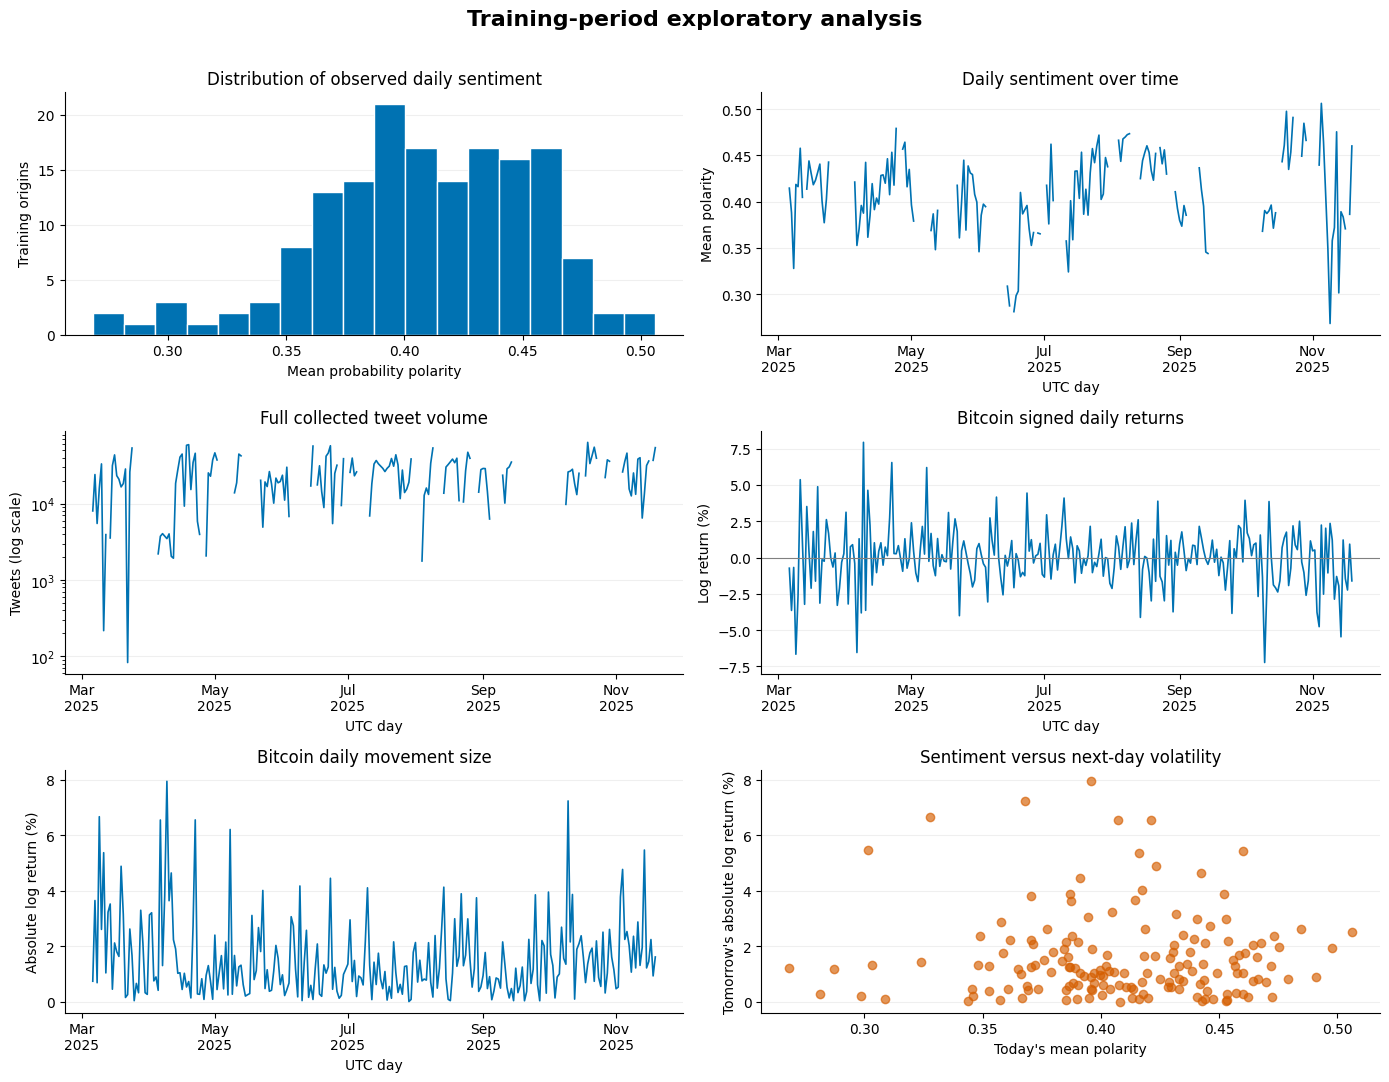

Use the displayed series and correlation table to describe associations; these do not establish causation.


In [21]:
training_calendar = aligned_daily.loc[train_data.index.min():train_data.index.max()].copy()
training_calendar['collected_volume'] = training_calendar['full_tweet_count'].where(
    training_calendar['has_sentiment'].astype(bool)
)
fig, axes = plt.subplots(3, 2, figsize=(14, 11))
axes[0, 0].hist(train_data['mean_polarity'], bins=18, color='#0072B2', edgecolor='white')
axes[0, 0].set(title='Distribution of observed daily sentiment',
               xlabel='Mean probability polarity', ylabel='Training origins')
series_specs = [
    (axes[0, 1], 'mean_polarity', 'Daily sentiment over time', 'Mean polarity'),
    (axes[1, 0], 'collected_volume', 'Full collected tweet volume', 'Tweets (log scale)'),
    (axes[1, 1], 'log_return_pct', 'Bitcoin signed daily returns', 'Log return (%)'),
    (axes[2, 0], 'abs_log_return_pct', 'Bitcoin daily movement size', 'Absolute log return (%)')
]
for ax, column, title, ylabel in series_specs:
    ax.plot(training_calendar.index, training_calendar[column], color='#0072B2', linewidth=1.2)
    ax.set(title=title, ylabel=ylabel, xlabel='UTC day')
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b\n%Y'))
axes[1, 0].set_yscale('log')
axes[1, 1].axhline(0, color='grey', linewidth=0.8)
axes[2, 1].scatter(train_data['mean_polarity'], train_data[TARGET_COLUMN],
                    alpha=0.65, color='#D55E00')
axes[2, 1].set(title='Sentiment versus next-day volatility',
               xlabel="Today's mean polarity", ylabel="Tomorrow's absolute log return (%)")
for ax in axes.flat:
    ax.spines[['top', 'right']].set_visible(False)
    ax.set_axisbelow(True)
    ax.grid(axis='y', alpha=0.2)
fig.suptitle('Training-period exploratory analysis', fontsize=16, fontweight='bold')
fig.tight_layout(rect=[0, 0, 1, 0.97])
fig.savefig(RUN_DIR / 'bitcoin_training_complete_eda.png', dpi=180, bbox_inches='tight')
plt.show()
print('Use the displayed series and correlation table to describe associations; these do not establish causation.')


## Q2.9 — Restore two model families and three input groups
### Assignment requirement 9

Linear regression and random forest each use market-only inputs, market plus
collected tweet volume, and market plus volume plus sentiment. The intermediate
control isolates sentiment's contribution from volume's contribution. All use
the same training observations. The forest has 200 trees, maximum depth 4,
minimum leaf size 5 and seed 42. These were fixed settings, not test-set tuning.

The default path loads the six fitted models. `REFIT_FORECAST_MODELS=True`
deliberately refits and replaces the forecasting bundle using the saved split;
it does not repeat CryptoBERT. Keep it False to preserve the completed models.


In [22]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
import sklearn
import joblib
import warnings

FEATURE_SETS = {
    'Market only': BASELINE_FEATURES,
    'Market + volume': CONTROL_FEATURES,
    'Market + volume + sentiment': ENHANCED_FEATURES
}
MODEL_FILE = RUN_DIR / 'bitcoin_volatility_models.joblib'
if not REFIT_FORECAST_MODELS:
    if not MODEL_FILE.is_file():
        raise FileNotFoundError(f'Restore the saved forecasting models: {MODEL_FILE}')
    model_bundle = joblib.load(MODEL_FILE)
    if not train_data.index.equals(pd.DatetimeIndex(model_bundle['train_dates'])):
        raise ValueError('Saved models were trained on different origins.')
    if not test_data.index.equals(pd.DatetimeIndex(model_bundle['test_dates'])):
        raise ValueError('Saved models reserve different test origins.')
    if model_bundle['target_column'] != TARGET_COLUMN:
        raise ValueError('Saved models use a different target.')
    saved_version = model_bundle.get('sklearn_version')
    if saved_version and saved_version != sklearn.__version__:
        warnings.warn(f'Saved sklearn version {saved_version}; current {sklearn.__version__}. '
                      'Use a compatible runtime if loading or prediction fails.')
    fitted_models = model_bundle['models']
    expected_names = {f'{family} | {group}' for family in ['Linear regression', 'Random forest']
                      for group in FEATURE_SETS}
    if set(fitted_models) != expected_names:
        raise ValueError('The saved bundle does not contain the expected six models.')
    rows = []
    for name, entry in fitted_models.items():
        if entry['features'] != FEATURE_SETS[entry['input_group']]:
            raise ValueError(f'{name}: saved predictor order differs.')
        rows.append({'Model': entry['family'], 'Inputs': entry['input_group'],
                     'Predictor_count': len(entry['features']), 'Training_rows': len(train_data)})
    model_summary = pd.DataFrame(rows)
    display(model_summary)
    print('Loaded six saved forecasting models. No fitting was repeated.')
else:
    # Q2.9 — Train two model approaches using three input groups.
    from sklearn.linear_model import LinearRegression
    from sklearn.ensemble import RandomForestRegressor
    import sklearn
    import joblib

    TARGET_COLUMN = "target_volatility_pct"

    FEATURE_SETS = {
        "Market only": BASELINE_FEATURES,
        "Market + volume": CONTROL_FEATURES,
        "Market + volume + sentiment": ENHANCED_FEATURES
    }

    y_train = train_data[TARGET_COLUMN]

    fitted_models = {}
    model_summary_rows = []

    for input_group, features in FEATURE_SETS.items():

        # Only today's information enters the predictors.
        assert TARGET_COLUMN not in features
        X_train = train_data[features]

        estimators = {
            "Linear regression": LinearRegression(),

            # Fixed settings keep the forest modest for our small dataset.
            "Random forest": RandomForestRegressor(
                n_estimators=200,
                max_depth=4,
                min_samples_leaf=5,
                random_state=42,
                n_jobs=-1
            )
        }

        for family, estimator in estimators.items():
            estimator.fit(X_train, y_train)

            model_name = f"{family} | {input_group}"

            fitted_models[model_name] = {
                "model": estimator,
                "features": list(features),
                "family": family,
                "input_group": input_group
            }

            model_summary_rows.append({
                "Model": family,
                "Inputs": input_group,
                "Predictor_count": len(features),
                "Training_rows": len(X_train)
            })

    model_summary = pd.DataFrame(model_summary_rows)
    display(model_summary)

    # Save fitted models and their input definitions for later restoration.
    model_bundle = {
        "models": fitted_models,
        "target_column": TARGET_COLUMN,
        "training_mean": float(y_train.mean()),
        "sklearn_version": sklearn.__version__,
        "train_dates": train_data.index,
        "test_dates": test_data.index
    }

    MODEL_FILE = RUN_DIR / "bitcoin_volatility_models.joblib"
    joblib.dump(model_bundle, MODEL_FILE)

    model_summary.to_csv(
        RUN_DIR / "bitcoin_volatility_model_setup.csv",
        index=False,
        encoding="utf-8-sig"
    )

    print("Models trained:", len(fitted_models))
    print("Saved:", MODEL_FILE)
    print("Test predictions and evaluation have not been run yet.")


,Model,Inputs,Predictor_count,Training_rows
0,Linear regression,Market only,2,160
1,Random forest,Market only,2,160
2,Linear regression,Market + volume,3,160
3,Random forest,Market + volume,3,160
4,Linear regression,Market + volume + sentiment,6,160
5,Random forest,Market + volume + sentiment,6,160


Loaded six saved forecasting models. No fitting was repeated.


## Q2.10 — Evaluate on the reserved test origins
### Assignment requirement 10

Predictions are recalculated from the saved models, which is inexpensive.
No fitting or sentiment inference occurs. Training mean, training median and
today's observed movement size provide three benchmarks. MAE and RMSE are
errors in percentage points; R² compares squared errors with the test-set mean.
Raw predictions are retained separately. Negative predictions are floored at
zero for evaluation; this affected none of the completed run's forecasts.


In [23]:
# Q2.10 — Evaluate saved models on the reserved test dates.
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score
)
import joblib

# Restore small saved files; no model training is repeated.
model_bundle = joblib.load(
    RUN_DIR / "bitcoin_volatility_models.joblib"
)
TARGET_COLUMN = model_bundle["target_column"]

test_data = pd.read_csv(
    RUN_DIR / "bitcoin_forecast_test.csv", index_col=0
)
test_data.index = pd.to_datetime(test_data.index, utc=True)
test_data.index.name = "day"
test_data["target_day"] = pd.to_datetime(
    test_data["target_day"], utc=True
)

assert test_data.index.equals(model_bundle["test_dates"])

train_targets = pd.read_csv(
    RUN_DIR / "bitcoin_forecast_train.csv",
    usecols=[TARGET_COLUMN]
)[TARGET_COLUMN]

actual = test_data[TARGET_COLUMN].to_numpy()

# Benchmarks use training information or today's observed volatility.
raw_forecasts = {
    "Benchmark | Training mean": np.full(
        len(test_data), model_bundle["training_mean"]
    ),
    "Benchmark | Training median": np.full(
        len(test_data), train_targets.median()
    ),
    "Benchmark | Persistence": (
        test_data["abs_log_return_pct"].to_numpy()
    )
}

# Predict using the same inputs each saved model was trained with.
for name, entry in model_bundle["models"].items():
    raw_forecasts[name] = entry["model"].predict(
        test_data[entry["features"]]
    )

test_predictions = test_data[["target_day"]].copy()
test_predictions["actual_volatility_pct"] = actual
raw_predictions = test_predictions.copy()
evaluation_rows = []

for name, raw_prediction in raw_forecasts.items():
    raw_prediction = np.asarray(raw_prediction)

    # Volatility cannot be negative. Preserve raw forecasts separately.
    prediction = np.maximum(raw_prediction, 0)

    raw_predictions[name] = raw_prediction
    test_predictions[name] = prediction

    evaluation_rows.append({
        "Model": name,
        "MAE": mean_absolute_error(actual, prediction),
        "RMSE": np.sqrt(mean_squared_error(actual, prediction)),
        "R_squared": r2_score(actual, prediction),
        "Negative_raw_forecasts": int((raw_prediction < 0).sum())
    })

model_evaluation = pd.DataFrame(evaluation_rows).sort_values("MAE")

print("Test rows evaluated:", len(test_data))
print("MAE and RMSE are measured in percentage points.")
display(model_evaluation.round(4))

# Save predictions and evaluation so they survive runtime resets.
test_predictions.to_csv(
    RUN_DIR / "bitcoin_test_predictions.csv",
    encoding="utf-8-sig"
)
raw_predictions.to_csv(
    RUN_DIR / "bitcoin_test_predictions_raw.csv",
    encoding="utf-8-sig"
)
model_evaluation.to_csv(
    RUN_DIR / "bitcoin_volatility_model_evaluation.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Saved test predictions, raw predictions and evaluation to Drive.")

Test rows evaluated: 40
MAE and RMSE are measured in percentage points.


,Model,MAE,RMSE,R_squared,Negative_raw_forecasts
3,Linear regression | Market only,1.1340,1.6331,0.3492,0
8,Random forest | Market + volume + sentiment,1.1572,1.8077,0.2027,0
1,Benchmark | Training median,1.1660,2.0923,-0.0682,0
5,Linear regression | Market + volume,1.1664,1.5938,0.3802,0
7,Linear regression | Market + volume + sentiment,1.1715,1.5944,0.3797,0
0,Benchmark | Training mean,1.1832,2.0278,-0.0033,0
6,Random forest | Market + volume,1.2262,1.8085,0.2020,0
4,Random forest | Market only,1.2924,2.0717,-0.0472,0
2,Benchmark | Persistence,1.6730,2.4669,-0.4849,0


Saved test predictions, raw predictions and evaluation to Drive.


## Q2.11 — Incremental sentiment value and forecast comparison
### Assignment requirement 11

Compare each enhanced model with the same family's market-plus-volume model.
Positive percentage improvement means lower test error after adding sentiment.
The final charts use the accepted layout. Equally spaced evaluated dates are
explicitly labelled; that spacing does not represent calendar elapsed time.


In [24]:
# Q2.11 — Summarise sentiment's contribution and visualise forecasts.
scores = model_evaluation.set_index("Model")
sentiment_comparison_rows = []

for family in ["Linear regression", "Random forest"]:
    control = scores.loc[f"{family} | Market + volume"]
    enhanced = scores.loc[f"{family} | Market + volume + sentiment"]

    sentiment_comparison_rows.append({
        "Model": family,
        "MAE_without_sentiment": control["MAE"],
        "MAE_with_sentiment": enhanced["MAE"],
        "MAE_improvement_pct": (
            100 * (control["MAE"] - enhanced["MAE"]) / control["MAE"]
        ),
        "RMSE_improvement_pct": (
            100 * (control["RMSE"] - enhanced["RMSE"]) / control["RMSE"]
        )
    })

sentiment_comparison = pd.DataFrame(sentiment_comparison_rows)
display(sentiment_comparison.round(3))
print("Positive improvement = lower error after adding sentiment.")

sentiment_comparison.to_csv(
    RUN_DIR / "bitcoin_sentiment_incremental_value.csv",
    index=False,
    encoding="utf-8-sig"
)


,Model,MAE_without_sentiment,MAE_with_sentiment,MAE_improvement_pct,RMSE_improvement_pct
0,Linear regression,1.166,1.172,-0.435,-0.041
1,Random forest,1.226,1.157,5.622,0.042


Positive improvement = lower error after adding sentiment.


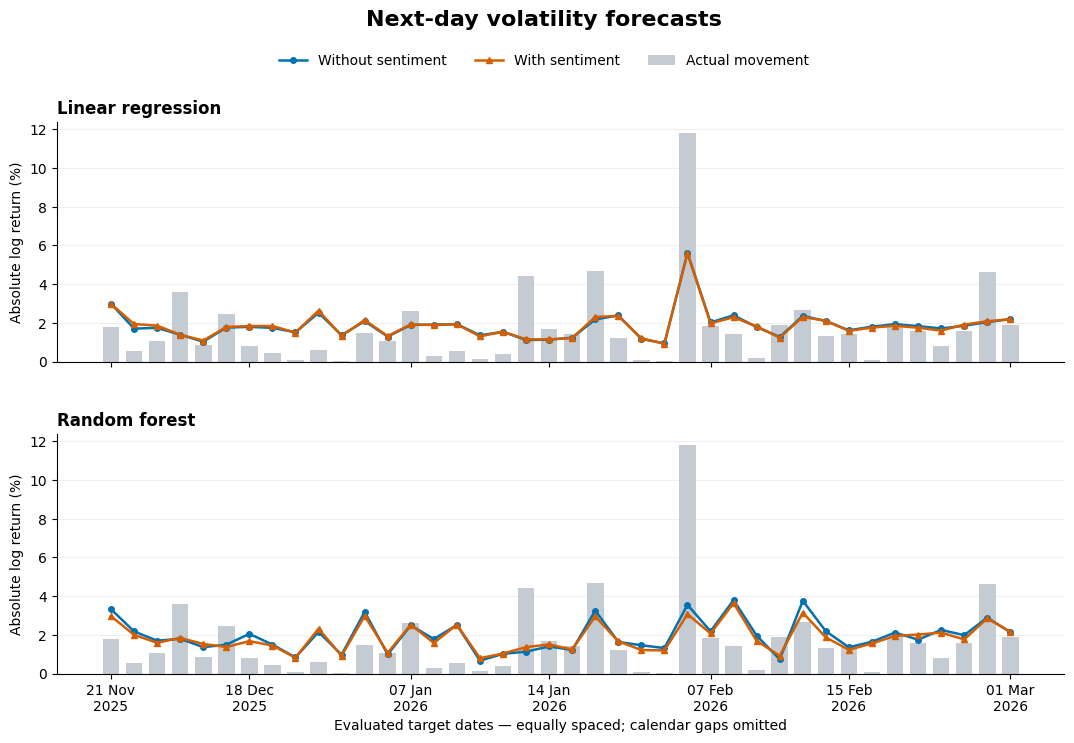

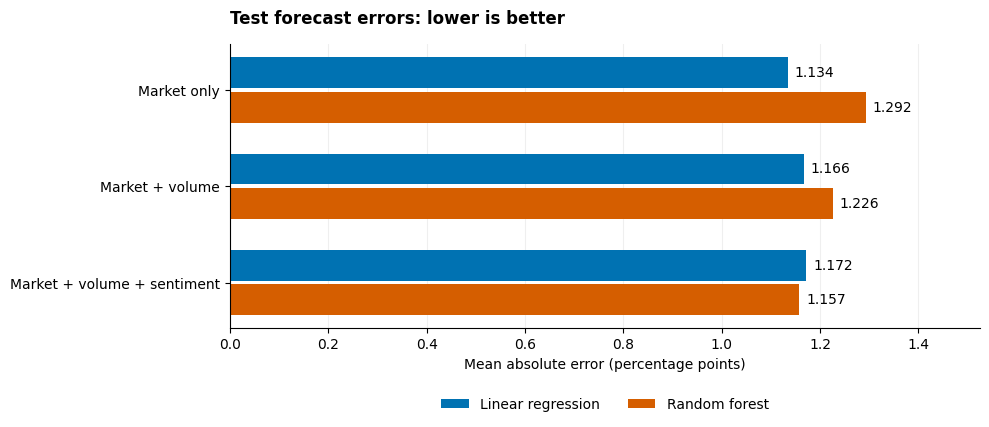

In [25]:
# Q2.11 — Clearer forecast and error charts.
p = test_predictions.copy()
p["target_day"] = pd.to_datetime(p["target_day"], utc=True)
p = p.sort_values("target_day").reset_index(drop=True)
x = np.arange(len(p))

BLUE = "#0072B2"
ORANGE = "#D55E00"

def tidy_axis(ax):
    ax.set_axisbelow(True)
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)

# Figure 1: actual movements versus forecasts with/without sentiment.
fig, axes = plt.subplots(
    2, 1, figsize=(13, 8), sharex=True, sharey=True
)

for ax, family in zip(axes, ["Linear regression", "Random forest"]):
    ax.bar(
        x, p["actual_volatility_pct"], width=0.72,
        color="#C4CBD3", label="Actual movement", zorder=2
    )

    for group, colour, marker, label in [
        ("Market + volume", BLUE, "o", "Without sentiment"),
        ("Market + volume + sentiment", ORANGE, "^", "With sentiment")
    ]:
        ax.plot(
            x, p[f"{family} | {group}"],
            color=colour, marker=marker, markersize=4,
            linewidth=1.8, label=label, zorder=3
        )

    ax.set_title(family, loc="left", fontweight="bold")
    ax.set_ylabel("Absolute log return (%)")
    ax.set_ylim(bottom=0)
    ax.grid(axis="y", alpha=0.2)
    ax.grid(axis="x", visible=False)
    tidy_axis(ax)

ticks = np.unique(np.linspace(0, len(p) - 1, 7).astype(int))
axes[-1].set_xticks(ticks)
axes[-1].set_xticklabels(
    p.loc[ticks, "target_day"].dt.strftime("%d %b\n%Y")
)
axes[-1].set_xlabel(
    "Evaluated target dates — equally spaced; calendar gaps omitted"
)

fig.suptitle(
    "Next-day volatility forecasts", fontsize=16, fontweight="bold"
)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles, labels, loc="upper center",
    bbox_to_anchor=(0.5, 0.94), ncol=3, frameon=False
)
fig.subplots_adjust(top=0.84, bottom=0.15, hspace=0.30)
fig.savefig(
    RUN_DIR / "bitcoin_forecast_comparison_clean.png",
    dpi=200, bbox_inches="tight"
)
plt.show()

# Figure 2: compare all six models using test MAE.
scores = model_evaluation.set_index("Model")
groups = [
    "Market only", "Market + volume", "Market + volume + sentiment"
]
positions = np.arange(len(groups))

fig, ax = plt.subplots(figsize=(10, 4.5))

for offset, family, colour in [
    (-0.18, "Linear regression", BLUE),
    (0.18, "Random forest", ORANGE)
]:
    values = [
        scores.loc[f"{family} | {group}", "MAE"] for group in groups
    ]
    bars = ax.barh(
        positions + offset, values, height=0.32,
        color=colour, label=family
    )
    ax.bar_label(bars, fmt="%.3f", padding=5, fontsize=10)

ax.set_yticks(positions)
ax.set_yticklabels(groups)
ax.invert_yaxis()
ax.set_xlim(0, max(bar.get_width() for bar in ax.patches) * 1.18)
ax.set_xlabel("Mean absolute error (percentage points)")
ax.set_title(
    "Test forecast errors: lower is better",
    loc="left", fontweight="bold", pad=15
)
ax.grid(axis="x", alpha=0.2)
ax.grid(axis="y", visible=False)
ax.legend(
    loc="upper center", bbox_to_anchor=(0.5, -0.20),
    ncol=2, frameon=False
)
tidy_axis(ax)

plt.tight_layout()
fig.savefig(
    RUN_DIR / "bitcoin_model_mae_comparison.png",
    dpi=200, bbox_inches="tight"
)
plt.show()

The graphs examine whether adding tweet sentiment improves forecasts of the following day’s Bitcoin volatility, measured using absolute percentage log returns. They use the 40 observations reserved for testing.
Forecast comparison graphs
The upper panel shows linear regression; the lower panel shows random forest. In both:
- Grey bars: actual price-movement size on the target day.
- Blue line: forecasts using market information and tweet volume.
- Orange line: forecasts using those inputs plus sentiment.
A forecast is closer to the actual outcome when its line approaches the top of the corresponding grey bar.
The blue and orange lines overlap closely in linear regression, showing that adding sentiment changes its forecasts very little. They differ more in random forest, although both approaches substantially underestimate the largest movement, approximately 12%.
Dates are equally spaced in chronological order. Each position represents one evaluated observation; the spacing does not represent elapsed calendar time.
Forecast-error bar chart
Here, blue represents linear regression and orange represents random forest. Each group compares their mean absolute error using a different set of inputs. Shorter bars indicate smaller average errors.
Market-only linear regression achieves the lowest MAE, approximately 1.134 percentage points. Adding sentiment slightly worsens linear regression’s MAE, from approximately 1.1664 to 1.1715, but improves random forest’s MAE from 1.226 to 1.157, approximately 5.6%.
Together, the graphs show a modest benefit from sentiment in random forest, rather than consistent improvement across models. This finding applies to this test sample and remains subject to the supplied timestamp inconsistencies and the earlier 43% manual agreement for sentiment classification.

### Q2.11b — Interpret fitted feature contributions

Linear coefficients are multiplied by each input's training standard deviation.
They indicate fitted prediction changes in percentage points for a one-standard-
deviation increase, holding other inputs fixed. They are not fully standardised
coefficients, significance tests or causal effects. Correlated inputs can make
individual coefficients unstable.

Forest importance is each input's share of training split/error-reduction
importance. It is unsigned and is not the percentage of volatility explained
or proof of a contribution to test performance. The held-out comparisons above
remain the evidence about incremental predictive value.


In [26]:
import joblib
from IPython.display import display

# Q2.11b — Interpret the fitted models
#
# We examine the models that include market information, tweet volume,
# and sentiment. This supports discussion of their forecasting results.
# Existing models are loaded; no training or sentiment scoring is repeated.



# Load the saved models and their original training observations.
interpret_bundle = joblib.load(
    RUN_DIR / "bitcoin_volatility_models.joblib"
)

interpret_train = pd.read_csv(
    RUN_DIR / "bitcoin_forecast_train.csv",
    index_col=0
)
interpret_train.index = pd.to_datetime(
    interpret_train.index, utc=True
)

# Confirm that these observations match the saved models' training dates.
saved_train_dates = pd.DatetimeIndex(
    pd.to_datetime(interpret_bundle["train_dates"], utc=True)
)

if not interpret_train.index.equals(saved_train_dates):
    raise ValueError(
        "The training CSV does not match the saved models' training dates."
    )

linear_entry = interpret_bundle["models"][
    "Linear regression | Market + volume + sentiment"
]

forest_entry = interpret_bundle["models"][
    "Random forest | Market + volume + sentiment"
]

# Linear regression:
# Multiply each coefficient by its predictor's training standard deviation.
# This makes variables measured in different units easier to compare.
linear_coefficients = pd.Series(
    linear_entry["model"].coef_,
    index=linear_entry["features"]
)

training_sd = interpret_train[
    linear_entry["features"]
].std(ddof=0)

linear_changes = (
    linear_coefficients * training_sd
).rename("Linear_change_per_1SD_pp")

# Random forest:
# Extract each variable's share of the training split importance.
forest_importance = pd.Series(
    100 * forest_entry["model"].feature_importances_,
    index=forest_entry["features"],
    name="Forest_split_importance_pct"
)

feature_interpretation = pd.concat(
    [linear_changes, forest_importance],
    axis=1
).sort_values(
    "Forest_split_importance_pct",
    ascending=False
)

feature_interpretation.index.name = "Feature"

# Save the full-precision results for the report.
interpretation_path = (
    RUN_DIR / "bitcoin_model_feature_interpretation.csv"
)
feature_interpretation.to_csv(interpretation_path)

display(feature_interpretation.round(4))

print("\nLinear change: percentage points of predicted volatility.")
print("Forest importance: relative importance within the fitted forest.")
print(f"\nSaved to: {interpretation_path}")

,Linear_change_per_1SD_pp,Forest_split_importance_pct
Feature,,
log_tweet_volume,-0.3445,36.9633
log_return_pct,-0.2374,28.9317
positive_share,0.0223,14.0414
abs_log_return_pct,0.1756,9.3698
negative_share,0.0905,5.7080
mean_polarity,0.0607,4.9857



Linear change: percentage points of predicted volatility.
Forest importance: relative importance within the fitted forest.

Saved to: /content/drive/MyDrive/Assignment_4/Completed_Run/bitcoin_model_feature_interpretation.csv


- Tweet volume was the random forest’s most important input, accounting for 36.96% of its training split importance, followed by Bitcoin’s signed return at 28.93%.
- Positive sentiment share was the strongest sentiment input, at 14.04%. Negative share and mean polarity contributed approximately 5.71% and 4.99%.
- In the linear model, a one-standard-deviation increase in tweet volume was associated with 0.3445 percentage points lower predicted volatility, holding other inputs fixed. The sentiment variables had smaller fitted changes.
These are fitted associations and training split importances, not causal effects or percentages of volatility explained.


### Question 2 — Findings and limitations

This analysis examined whether daily tweet sentiment improved forecasts of next-day Bitcoin volatility beyond market information and tweet volume. Volatility was represented by the absolute daily percentage log return. Models used a chronological split of 160 training observations and 40 test observations.

**Forecasting results**

The market-only linear regression achieved the lowest test MAE, approximately **1.134 percentage points**. The linear regression using market information and tweet volume achieved the lowest RMSE, approximately **1.594 percentage points**.

Adding sentiment to the random forest reduced MAE by approximately **5.6%** compared with the same model using market information and tweet volume. However, its RMSE improvement was only approximately **0.04%**. Adding sentiment slightly worsened the linear regression’s errors.

Consequently, sentiment provided a modest benefit for one model and one error measure, but did not consistently improve forecasting. The forecast graphs also showed that the models underestimated the largest observed volatility spike.

**Limitations**

CryptoBERT scored **40,083 sampled tweets**, rather than the full corpus. Its accuracy on the 100 manually labelled tweets was **43%**, indicating substantial disagreement with human judgement. These predictions should therefore be treated as noisy estimates of sentiment.

Missing sentiment days reduced the usable forecasting dataset to 200 observations. The 40 test observations span discontinuous calendar dates; the cleaner graphs display them equally spaced in chronological order.

The supplied tweet timestamps were retained despite the previously identified date concerns. The results are conditional on that supplied timeline: potentially incorrect timestamps could misalign tweets with market events and undermine a historical forecasting interpretation.

**Conclusion**

Within this dataset and test split, the evidence does not establish a consistent forecasting advantage from CryptoBERT sentiment. Market information provided competitive forecasts, while sentiment offered a limited improvement in the random forest’s MAE. Broader conclusions would require reliable timestamp alignment, stronger sentiment validation, and evaluation across additional chronological test periods.

## Submission coverage and saved outputs

| Assignment area | Evidence in this notebook |
|---|---|
| Q1 acquisition, cleaning and EDA | Q1.1–Q1.2b; original computation in Appendix A |
| Q1 representations, methods and topic count | Count/LDA and TF-IDF/NMF; Q1.3–Q1.4 |
| Q1 labels, keywords, examples and interpretation | Q1.5–Q1.5b, all nine final topics |
| Q1 temporal changes and charts | Q1.6–Q1.6b, monthly shares and change summary |
| Q1 required assignment file | Q1.7, completed export includes cleaned text |
| Q2 sentiment generation and validation | Q2.1–Q2.4; 100 manual labels and error cases |
| Q2 aggregation, target, alignment and EDA | Q2.5–Q2.8b |
| Q2 approaches and chronological evaluation | Q2.9–Q2.10; six models and three benchmarks |
| Q2 predictive value and limitations | Q2.11–Q2.11b and findings/conclusion |

Run the following inventory after the analysis. A missing export or plot needs
the relevant producing cell; it does not require repeating the full pipeline.
A fresh Colab run is still needed to verify this notebook against your actual
Drive account. Add the report and PowerPoint as separate submission files.


In [27]:
submission_outputs = [
    'bitcoin_nmf_topic_assignments_complete.csv',
    'nmf_final_topic_interpretation.csv', 'nmf_final_representative_tweets.csv',
    'nmf_topic_change_summary.csv', 'bitcoin_topic_saved_data_eda.png',
    'bitcoin_sentiment_scored.csv', 'cryptobert_manual_validation.csv',
    'cryptobert_error_examples.csv', 'bitcoin_daily_sentiment.csv',
    'bitcoin_daily_market_features.csv', 'bitcoin_forecasting_dataset.csv',
    'bitcoin_forecast_train.csv', 'bitcoin_forecast_test.csv',
    'bitcoin_training_correlations.csv', 'bitcoin_training_complete_eda.png',
    'bitcoin_volatility_models.joblib', 'bitcoin_test_predictions.csv',
    'bitcoin_volatility_model_evaluation.csv', 'bitcoin_sentiment_incremental_value.csv',
    'bitcoin_forecast_comparison_clean.png', 'bitcoin_model_mae_comparison.png',
    'bitcoin_model_feature_interpretation.csv'
]
output_inventory = pd.DataFrame([
    {'File': name, 'Available': (RUN_DIR / name).is_file()} for name in submission_outputs
])
display(output_inventory)
missing_outputs = output_inventory.loc[~output_inventory['Available'], 'File'].tolist()
if missing_outputs:
    raise FileNotFoundError(f'Finish the relevant cells for these missing outputs: {missing_outputs}')
print('All listed analysis outputs are present in Drive.')
print('Save this executed notebook; add both group names to your submission filenames.')


,File,Available
0,bitcoin_nmf_topic_assignments_complete.csv,True
1,nmf_final_topic_interpretation.csv,True
2,nmf_final_representative_tweets.csv,True
3,nmf_topic_change_summary.csv,True
4,bitcoin_topic_saved_data_eda.png,True
5,bitcoin_sentiment_scored.csv,True
6,cryptobert_manual_validation.csv,True
7,cryptobert_error_examples.csv,True
8,bitcoin_daily_sentiment.csv,True
9,bitcoin_daily_market_features.csv,True


All listed analysis outputs are present in Drive.
Save this executed notebook; add both group names to your submission filenames.
